> **In this repository.** Reads every finished run (fine-tuning notebooks, logistic-regression baselines, BioCLIP 2 candidates), compares them on `val.csv`, and picks the two models that go to the test set: one BioCLIP 2 configuration and the best fine-tuned model. The logistic-regression probes are baselines only and are never selected. It was run on Google Colab against the team's Google Drive, so its paths point to Drive; the saved outputs are the record of what it produced. To re-run it from this repository, change the data path to the folder made by `src/invasive_clf/data/download_images.py` (see `data/README.md`).

# Final model comparison

This notebook reads every finished run under `modeling_runs/` (the fine-tuning experiment notebooks, `17_logreg_baselines.ipynb` and the BioCLIP 2 notebooks 14 to 16) and picks the **two models that go to the test set**, one per series:

| series | what competes | chosen configuration |
|---|---|---|
| **BioCLIP 2** | every frozen-feature method built on BioCLIP 2 ViT-L/14 | a fixed configuration (one-shot evaluation on test set) |
| **fine-tuned models** | the best of each fine-tuned pretrained model (PlantNet DINOv3, DINOv3, SigLIP 2, ConvNeXt-Tiny, the five ResNets) | the best fine-tuned model (to be fine-tuned on the full training set) |

The logistic-regression probes on frozen features (`logreg_<backbone>`) are **baselines for comparison only**: each fine-tuned backbone is compared with its own probe (the five ResNets with the single ResNet-50 probe), but no probe is ever selected. The two choices and their hyperparameters are written to `modeling_runs/final_selection/`, which the final training + test-evaluation notebook reads. Validation metrics come from the `metrics_final.json`, `config.json`, `decisions.json`, `history.csv` and `val_predictions.csv` files the other notebooks wrote.

Backbones without runs appear as blank rows, so re-running the notebook after training new models and iterations fills them in and refreshes every table, figure and output file.

## How the notebook is organized

* **Section 1** configures the comparison: the metric that ranks runs, the two series and how each one picks its winner (`SERIES`, with a per-series override and the reason for it), the backbones with their display names, the probe each one is compared with (`probe`) and the series each one belongs to (`series`), and how a backbone's "best fine-tune" is chosen.
* **Section 2** finds `modeling_runs/` (Drive on Colab, repo-relative locally) and **Section 3** loads every run into one table with its `kind` (what sort of model it is: fine-tune, logistic-regression probe, kNN, zero-shot, ...) and its `series`.
* **Sections 4 to 6** are the fine-tuned series: the backbone matrix (probe vs fine-tune), the iteration trajectories and the training curves of the selected runs.
* **Section 7** is the BioCLIP 2 series: every frozen-feature method next to each other, and the fixed configuration that goes to the test set.
* **Section 8** names the two selected models and builds the shortlist (the selected models plus the best alternatives of each series) that **Sections 9 to 12** examine side by side: all runs at a glance, per-class F1, the error analysis on the `not_invasive` groups, and bootstrap confidence intervals, paired within each series.
* **Section 13** writes `final_selection/` (`final_models.json`, one config and one metrics file per series, the CSV tables and the figures).

### How a backbone's best fine-tune is chosen

The experiment notebooks record an `accept`/`reject` decision per iteration; the configuration a notebook converged on is the last accepted iteration (its `config.json` holds the complete hyperparameters). That is the default (`FINETUNE_SELECTION = "accepted"`); choosing `"max"` instead takes the highest-scoring finished run whatever its decision; the notebook prints where the two rules disagree.

## 0. Environment

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules or os.path.isdir("/content")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
import copy, datetime, json, re, shutil, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Plot style shared with the experiment notebooks so the figures sit next to each other in a report.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
C_BLUE, C_BLUE_LIGHT, C_ORANGE, C_GRAY, C_INK = "#2a78d6", "#a7c7ec", "#eb6834", "#9a9995", "#52514e"
# One color per kind of run (what type of model it is), used in every figure that mixes kinds.
KIND_COLORS = {"finetune": C_BLUE, "logreg": C_ORANGE, "knn": "#2f9e6e", "zeroshot": "#9452d6", "knn+zeroshot": "#d6476f", "other": C_GRAY}
KIND_LABELS = {"finetune": "fine-tuned backbone", "logreg": "logistic regression linear probe", "knn": "kNN on frozen features",
               "zeroshot": "zero-shot (image-text)", "knn+zeroshot": "kNN + zero-shot", "other": "other evaluation"}
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)


def blank(df: pd.DataFrame, decimals=4) -> pd.DataFrame:
    """Round and show missing values as empty cells (the blank rows of backbones that have not been run yet)."""
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_float_dtype(out[c]):
            finite = out[c].dropna()
            out[c] = out[c].astype("Int64") if len(finite) and (finite == finite.round()).all() and finite.abs().max() < 1e6 else out[c].round(decimals)
    return out.astype(object).where(out.notna(), "")

## 1. Configuration

Everything that decides the outcome of the comparison is in this cell.

In [3]:
RUNS_DIR_OVERRIDE = None             # e.g. "/path/to/modeling_runs"; None = Team Drive on Colab, else <repo root>/modeling_runs
OUTPUT_SUBFOLDER = "final_selection" # written under RUNS_DIR; read by the final training + test notebook

SELECT_METRIC = "macro_f1_invasive"  # primary validation metric: ranks iterations, backbones and candidates
KPI_METRIC = "top1_acc_all"          # tie-break and guard-rail, reported next to the primary metric
FINETUNE_SELECTION = "accepted"      # "accepted": the last accepted iteration of each experiment notebook; "max": highest SELECT_METRIC

# The two series. Each one sends exactly one model to the test set. "mode" says what competes and how the winner is used there:
# "frozen" = the best run of every family of the series (nothing is trained again; the final notebook loads the saved run and scores
# the test set once); "finetune" = the iteration each fine-tuning notebook of the series converged on (FINETUNE_SELECTION), the best
# of them across backbones, fine-tuned on the full training set. "override" (a run id "<family>/<iteration>") replaces the rule's pick
# and is reported next to it; "note" records the reason in final_models.json. The dict order is the display order.
SERIES = {
    "bioclip2": {"label": "BioCLIP 2 (frozen features, no fine-tuning)", "mode": "frozen",
                 "override": "bioclip2_zeroshot_full/00_baseline",
                 "note": "The rule picks bioclip2_knn_zeroshot_full (val macro-F1 0.973), which ties with bioclip2_zeroshot_full (0.967; 95% interval "
                         "of the paired difference -0.014 to +0.002). In the unknown-species rehearsal of notebook 16 (species hidden from the model "
                         "on val) the kNN + zero-shot combination flags 10-15% of the unknown-species photos as invasive against about 4% for "
                         "zero-shot-full, so zero-shot-full is the better model for the test set."},
    "finetune": {"label": "fine-tuned models", "mode": "finetune",
                 "override": "dinov3_vits16/04_pool_cls_patchmean",
                 "note": "SigLIP 2 ViT-B/16 scores slightly higher on validation (0.762 vs 0.751, within bootstrap noise) but has four times "
                         "the parameters of DINOv3 ViT-S/16; the smaller model is chosen."},
}
FINETUNE_MAX_PARAMS_M = 100.0        # every backbone of a fine-tuned series must be below this (BioCLIP 2's 304M puts it in its own, frozen series)
TOP_K_PER_SERIES = 4                 # alternatives per series kept on the shortlist of Sections 9 to 12 (including the selected models)
N_BOOTSTRAP, BOOTSTRAP_SEED = 1000, 0

# Backbones in display order (keys = BACKBONE_REGISTRY keys = modeling_runs/<key>/). "series" is the key of SERIES the backbone and every
# family built on it belong to; it defaults to "finetune". "probe" names the backbone whose logistic-regression baseline
# (modeling_runs/logreg_<probe>/00_baseline) the fine-tunes are compared with; it defaults to the backbone itself. All ResNets point at
# "resnet50", so the ResNet family is compared together against one linear probe. "group" collects variants of one architecture: they
# share a panel in the iteration plot and a color family in the overlays; it defaults to the display name.
BACKBONES = {
    "bioclip2":             {"display": "BioCLIP 2 ViT-L/14",       "arch": "ViT", "params_M": 304.0, "pretraining": "BioCLIP 2 image-text (TreeOfLife-200M)", "series": "bioclip2"},
    "siglip2_base":         {"display": "SigLIP 2 ViT-B/16",        "arch": "ViT", "params_M": 92.9, "pretraining": "SigLIP 2 image-text (WebLI)"},
    "plantnet_dinov3_vits": {"display": "PlantNet DINOv3 ViT-S/16", "arch": "ViT", "params_M": 21.6, "pretraining": "DINOv3 + Pl@ntNet-300K fine-tune"},
    "dinov3_vits16":        {"display": "DINOv3 ViT-S/16",          "arch": "ViT", "params_M": 21.6, "pretraining": "DINOv3 self-supervised (LVD-1689M)"},
    "convnext_tiny":        {"display": "ConvNeXt-Tiny",            "arch": "CNN", "params_M": 27.8, "pretraining": "ImageNet-22k -> 1k"},
    "resnet18":             {"display": "ResNet-18",                "arch": "CNN", "params_M": 11.2, "pretraining": "ImageNet-1k (timm a1)", "group": "ResNet", "probe": "resnet50"},
    "resnet34":             {"display": "ResNet-34",                "arch": "CNN", "params_M": 21.3, "pretraining": "ImageNet-1k (timm a1)", "group": "ResNet", "probe": "resnet50"},
    "resnet50":             {"display": "ResNet-50",                "arch": "CNN", "params_M": 23.5, "pretraining": "ImageNet-1k (timm a1)", "group": "ResNet", "probe": "resnet50"},
    "resnet101":            {"display": "ResNet-101",               "arch": "CNN", "params_M": 42.5, "pretraining": "ImageNet-1k (timm a1)", "group": "ResNet", "probe": "resnet50"},
    "resnet152":            {"display": "ResNet-152",               "arch": "CNN", "params_M": 58.1, "pretraining": "ImageNet-1k (timm a1)", "group": "ResNet", "probe": "resnet50"},
}
for _key, _info in BACKBONES.items():
    _info.setdefault("group", _info["display"]); _info.setdefault("probe", _key); _info.setdefault("series", "finetune")
PROBE_OF = {k: v["probe"] for k, v in BACKBONES.items()}                  # backbone -> backbone whose probe is its baseline
GROUPS = list(dict.fromkeys(v["group"] for v in BACKBONES.values()))      # display order
FINETUNED_SERIES = [s for s, v in SERIES.items() if v["mode"] == "finetune"]
FROZEN_SERIES = [s for s, v in SERIES.items() if v["mode"] == "frozen"]
assert all(p in BACKBONES for p in PROBE_OF.values()), "every probe must be a key of BACKBONES"
assert all(v["series"] in SERIES for v in BACKBONES.values()), "every backbone's series must be a key of SERIES"
assert all(v["mode"] in ("frozen", "finetune") for v in SERIES.values())
assert all(v["params_M"] < FINETUNE_MAX_PARAMS_M for v in BACKBONES.values() if v["series"] in FINETUNED_SERIES), \
    f"a backbone of {FINETUNE_MAX_PARAMS_M:.0f}M parameters or more is in a fine-tuned series"
assert all(v["override"] is None or v["override"].count("/") == 1 for v in SERIES.values()), 'an override is "<family>/<iteration>"'

# Kinds of families that are neither a BACKBONES fine-tune nor a logreg_<key> probe and whose config.json has no "method" field
# (notebook 16 writes "method": knn / zero_shot / knn+zero_shot). Otherwise the kind is read from the folder name (knn, zeroshot).
FAMILY_KINDS = {"bioclip2_probe": "logreg"}        # notebook 15: a linear head trained on frozen BioCLIP 2 features
METHOD_KINDS = {"knn": "knn", "zero_shot": "zeroshot", "knn+zero_shot": "knn+zeroshot", "logreg": "logreg"}
SERIES_MARKERS = dict(zip(SERIES, ["^", "D", "o", "s", "v", "P"]))         # marker per series in the scatter plot

# One fixed color per group (assigned by position, never cycled). Inside a multi-member group the members get lightness steps of the
# group color, lightest for the smallest model, so the ResNet depths read as one ordered family in the overlays.
SERIES_COLORS = ["#2a78d6", "#eb6834", "#2f9e6e", "#9452d6", "#d6476f", "#0e9bb8", "#9c7a0a", "#5a5fd1"]   # 8 slots, validated for CVD separation
assert len(GROUPS) <= len(SERIES_COLORS), "more groups than color slots: merge groups or extend the validated palette"
GROUP_COLORS = dict(zip(GROUPS, SERIES_COLORS))


def shade(hex_color: str, t: float) -> str:
    rgb = [int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]
    target = 0 if t > 0 else 255
    return "#" + "".join(f"{int(round(c + (target - c) * abs(t))):02x}" for c in rgb)


BACKBONE_COLORS = {}
for _g in GROUPS:
    _members = [k for k, v in BACKBONES.items() if v["group"] == _g]
    for _k, _t in zip(_members, np.linspace(-0.45, 0.45, len(_members)) if len(_members) > 1 else [0.0]):
        BACKBONE_COLORS[_k] = shade(GROUP_COLORS[_g], float(_t))

SCALAR_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive", "threshold",
                  "bin_precision_invasive", "bin_recall_invasive", "bin_f1_invasive", "bin_ap_invasive", "bin_auroc_invasive",
                  "noninv_precision", "noninv_recall", "noninv_auroc", "macro_f1_all41"]
KEY_METRICS = ["macro_f1_invasive", "top1_acc_all", "macro_ap_invasive", "top1_recall_invasive", "top3_recall_invasive",
               "bin_precision_invasive", "bin_recall_invasive", "bin_auroc_invasive", "noninv_auroc", "threshold"]
NONE_LABEL = "not_invasive"
assert SELECT_METRIC in SCALAR_METRICS and KPI_METRIC in SCALAR_METRICS
assert FINETUNE_SELECTION in ("accepted", "max")
assert set(FAMILY_KINDS.values()) | set(METHOD_KINDS.values()) <= set(KIND_COLORS), "kinds must be keys of KIND_COLORS"

## 2. Paths

`RUNS_DIR` is `RUNS_DIR_OVERRIDE` if set, else the Team Drive `modeling_runs` on Colab, else the repo-relative folder. The output folder is created inside it.

In [4]:
_candidates = [RUNS_DIR_OVERRIDE,
               "/content/drive/MyDrive/fall-2026-DL-invasive-plants/modeling_runs",
               "/content/drive/Shareddrives/fall-2026-DL-invasive-plants/modeling_runs",
               "../../modeling_runs", "modeling_runs"]
RUNS_DIR = next((Path(p) for p in _candidates if p and Path(p).is_dir()), None)
assert RUNS_DIR is not None, f"modeling_runs folder not found; tried {_candidates}"
OUT_DIR = RUNS_DIR / OUTPUT_SUBFOLDER
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("RUNS_DIR:", RUNS_DIR.resolve()); print("OUT_DIR :", OUT_DIR.resolve())
print("families found:", sorted(p.name for p in RUNS_DIR.iterdir() if p.is_dir() and p.name != OUTPUT_SUBFOLDER))


RUNS_DIR: /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs
OUT_DIR : /content/drive/.shortcut-targets-by-id/1VxedFijuaqDrUGWdycVJebTUGmt3qkqk/fall-2026-DL-invasive-plants/modeling_runs/final_selection
families found: ['_image_cache', 'bioclip2_knn', 'bioclip2_knn_zeroshot_full', 'bioclip2_probe', 'bioclip2_zeroshot', 'bioclip2_zeroshot_full', 'convnext_tiny', 'dinov3_vits16', 'final_test', 'logreg_bioclip2', 'logreg_convnext_tiny', 'logreg_dinov3_vits16', 'logreg_plantnet_dinov3_vits', 'logreg_resnet50', 'logreg_siglip2_base', 'plantnet_dinov3_vits', 'resnet101', 'resnet152', 'resnet18', 'resnet34', 'resnet50', 'siglip2_base']


## 3. Load every run

A *family* is a first-level folder of `modeling_runs/` (`plantnet_dinov3_vits`, `logreg_siglip2_base`, `bioclip2_knn`, ...); a *run* is a sub-folder with a `metrics_final.json`. Each run gets a `kind` (what sort of model it is: sets the color and label in the figures), a `backbone` (the longest `BACKBONES` key the family name starts with, after a `logreg_` prefix) and the `series` of that backbone (`BACKBONES[key]["series"]`). Families built on no registered backbone get no series; they stay in `all_runs.csv` and the scatter plot only. The decision (`accepted` / `rejected` / `undecided`) comes from the family's `decisions.json`.

In [5]:
META_KEYS = {"iteration", "model_name", "overrides", "built_on_accepted", "threshold_grid", "backbone", "max_batches_per_epoch", "num_workers"}


def family_backbone(name: str):
    """The BACKBONES key a family is built on: logreg_dinov3_vits16 -> dinov3_vits16, bioclip2_knn_zeroshot_full -> bioclip2."""
    stem = name[len("logreg_"):] if name.startswith("logreg_") else name
    return max((k for k in BACKBONES if stem == k or stem.startswith(k + "_")), key=len, default=None)


def classify_family(name: str, cfg: dict):
    """(kind, backbone, series) of a family; cfg is the config.json of one of its runs."""
    backbone = family_backbone(name)
    if name.startswith("logreg_"):
        kind = "logreg"
    elif name in BACKBONES:
        kind = "finetune"
    elif name in FAMILY_KINDS:
        kind = FAMILY_KINDS[name]
    elif cfg.get("method") in METHOD_KINDS:
        kind = METHOD_KINDS[cfg["method"]]
    else:
        tokens = set(name.split("_"))
        kind = "knn+zeroshot" if {"knn", "zeroshot"} <= tokens else "knn" if "knn" in tokens else "zeroshot" if "zeroshot" in tokens else "other"
    return kind, backbone, (BACKBONES[backbone]["series"] if backbone else None)


def load_json(path: Path):
    return json.load(open(path)) if path.exists() else None


def load_runs() -> pd.DataFrame:
    rows = []
    for fam_dir in sorted(p for p in RUNS_DIR.iterdir() if p.is_dir() and p.name != OUTPUT_SUBFOLDER):
        metric_files = sorted(fam_dir.glob("*/metrics_final.json"))
        if not metric_files:
            continue
        decisions = load_json(fam_dir / "decisions.json") or []
        dec_by_name = {d["name"]: (d["decision"], i) for i, d in enumerate(decisions)}
        kind, backbone, series = classify_family(fam_dir.name, load_json(metric_files[0].parent / "config.json") or {})
        for f in metric_files:
            m = load_json(f); cfg = load_json(f.parent / "config.json") or {}
            decision, order = dec_by_name.get(f.parent.name, ("undecided", None))
            rows.append({"candidate": f"{fam_dir.name}/{f.parent.name}", "family": fam_dir.name, "iteration": f.parent.name, "kind": kind,
                         "series": series, "backbone": backbone, "decision": decision, "decision_order": order,
                         **{k: m.get(k, np.nan) for k in SCALAR_METRICS},
                         "best_epoch": m.get("best_epoch"), "epochs": m.get("epochs"), "train_minutes": m.get("train_minutes", np.nan),
                         "C": m.get("C", np.nan), "method": cfg.get("method", ""),
                         "overrides": json.dumps(cfg.get("overrides", {}), default=str) if cfg else "",
                         "has_history": (f.parent / "history.csv").exists(), "has_predictions": (f.parent / "val_predictions.csv").exists(),
                         "weights_file": next((n for n in ("best.pt", "best.joblib") if (f.parent / n).exists()), None),
                         "run_dir": str(f.parent.relative_to(RUNS_DIR)), "_config": cfg, "_metrics": m})
    df = pd.DataFrame(rows)
    assert len(df), f"no */*/metrics_final.json under {RUNS_DIR}"
    df["series_order"] = df["series"].map({s: i for i, s in enumerate(SERIES)}).fillna(len(SERIES))
    return df.sort_values(["series_order", "kind", "family", "iteration"]).drop(columns="series_order").reset_index(drop=True)


runs = load_runs()
by_run = runs.set_index("candidate")
print(f"{len(runs)} finished runs in {runs['family'].nunique()} families")
display(runs.groupby(["series", "kind", "family"], dropna=False, sort=False)
            .agg(runs=("iteration", "count"), accepted=("decision", lambda s: int((s == "accepted").sum())), best_macro_f1=(SELECT_METRIC, "max")).round(4))
show_cols = ["family", "iteration", "kind", "series", "decision", SELECT_METRIC, KPI_METRIC, "macro_ap_invasive", "bin_auroc_invasive", "threshold",
             "best_epoch", "train_minutes", "overrides"]
display(blank(runs[show_cols]))
runs.drop(columns=["_config", "_metrics"]).to_csv(OUT_DIR / "all_runs.csv", index=False)
for s in FROZEN_SERIES:
    ft_in_frozen = runs[(runs["series"] == s) & (runs["kind"] == "finetune")]["family"].unique()
    if len(ft_in_frozen):
        warnings.warn(f"series {s!r} is a frozen-feature series but {list(ft_in_frozen)} are fine-tuning families; they compete in it as they are")
unregistered = sorted(runs.loc[runs["series"].isna(), "family"].unique())
if unregistered:
    print(f"NOTE: {unregistered} are built on no registered backbone; they are in all_runs.csv and the scatter plot only")

76 finished runs in 20 families


runs  accepted  best_macro_f1
series   kind         family                                                    
bioclip2 knn          bioclip2_knn                    1         1         0.9635
         knn+zeroshot bioclip2_knn_zeroshot_full      1         1         0.9728
         logreg       bioclip2_probe                  9         0         0.9703
                      logreg_bioclip2                 1         1         0.9511
         zeroshot     bioclip2_zeroshot               3         1         0.9678
                      bioclip2_zeroshot_full          1         1         0.9668
finetune finetune     convnext_tiny                   9         4         0.7285
                      dinov3_vits16                   6         3         0.7514
                      plantnet_dinov3_vits            6         3         0.6997
                      resnet101                       6         5         0.4778
                      resnet152                       6         3         0.5063
                      resnet18                        5         4         0.3841
                      resnet34                        5         2         0.3439
                      resnet50                        5         4         0.4366
                      siglip2_base                    7         3         0.7476
         logreg       logreg_convnext_tiny            1         1         0.6677
                      logreg_dinov3_vits16            1         1         0.7625
                      logreg_plantnet_dinov3_vits     1         1         0.7152
                      logreg_resnet50                 1         1         0.3414
                      logreg_siglip2_base             1         1         0.6951

,family,iteration,kind,series,decision,macro_f1_invasive,top1_acc_all,macro_ap_invasive,bin_auroc_invasive,threshold,best_epoch,train_minutes,overrides
0,bioclip2_knn,00_baseline,knn,bioclip2,accepted,0.9635,0.9802,0.9751,0.9956,0.53,3,18.5088,{}
1,bioclip2_knn_zeroshot_full,00_baseline,knn+zeroshot,bioclip2,accepted,0.9728,0.9854,0.9916,0.9985,0.14,1,18.5227,{}
2,bioclip2_probe,bce40_random,logreg,bioclip2,undecided,0.7481,0.8123,0.8709,0.9431,0.01,39,,
3,bioclip2_probe,e_knn41,logreg,bioclip2,undecided,0.9612,0.9789,0.9804,0.997,0.52,,,
4,bioclip2_probe,e_linear_bce40,logreg,bioclip2,undecided,0.7481,0.8123,0.8709,0.9431,0.01,,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,logreg_convnext_tiny,00_baseline,logreg,finetune,accepted,0.6677,0.8417,0.7046,0.9249,0.05,6,37.1156,{}
72,logreg_dinov3_vits16,00_baseline,logreg,finetune,accepted,0.7625,0.8841,0.8011,0.949,0.11,7,37.3433,{}
73,logreg_plantnet_dinov3_vits,00_baseline,logreg,finetune,accepted,0.7152,0.8625,0.7591,0.9372,0.12,5,39.0281,{}
74,logreg_resnet50,00_baseline,logreg,finetune,accepted,0.3414,0.6781,0.3347,0.7814,0.04,3,46.006,{}


## 4. Fine-tuned series: linear probe vs fine-tuning per backbone

One row per backbone of the fine-tuned series (`SERIES[...]["mode"] == "finetune"`), blank where nothing has been run yet. `probe` is `logreg_<probe>/00_baseline` where `probe` is the backbone named in `BACKBONES[key]["probe"]`: the backbone itself, except for the ResNets, which are all compared with the single ResNet-50 probe (`probe_backbone` says which probe a row uses). `ft_baseline` is the fine-tuning notebook's `00_baseline` (the design doc's initial configuration); `ft_best` is the fine-tune chosen by `FINETUNE_SELECTION`. `gain` is `ft_best - probe` on each metric. `ft_changes` lists the hyperparameters of `ft_best` that differ from `ft_baseline`. The probes are the comparison only; the candidates of these series are the `ft_best` runs.

In [6]:
def config_changes(run_row, base_row) -> dict:
    """Hyperparameters of a run that differ from the family's 00_baseline (full configs from config.json)."""
    cfg, base = run_row["_config"], (base_row["_config"] if base_row is not None else {})
    keys = [k for k in cfg if k not in META_KEYS]
    return {k: cfg[k] for k in keys if k not in base or base[k] != cfg[k]}


def finetune_runs(backbone) -> pd.DataFrame:
    return runs[(runs["kind"] == "finetune") & (runs["family"] == backbone)]


def select_finetune(backbone, rule=FINETUNE_SELECTION):
    ft = finetune_runs(backbone)
    if ft.empty:
        return None
    acc = ft[ft["decision"] == "accepted"].sort_values("decision_order")
    if rule == "accepted" and len(acc):
        return acc.iloc[-1]
    if rule == "accepted":
        warnings.warn(f"{backbone}: no accepted iteration in decisions.json; falling back to the highest {SELECT_METRIC}")
    return ft.loc[ft[SELECT_METRIC].idxmax()]


def get_run(family, iteration):
    hit = runs[(runs["family"] == family) & (runs["iteration"] == iteration)]
    return hit.iloc[0] if len(hit) else None


FINETUNED_BACKBONES = [k for s in FINETUNED_SERIES for k, v in BACKBONES.items() if v["series"] == s]   # series order, then BACKBONES order
rows, selected = [], {}
for key in FINETUNED_BACKBONES:
    info = BACKBONES[key]
    probe = get_run(f"logreg_{PROBE_OF[key]}", "00_baseline")                 # the backbone's own probe, or the shared one (ResNets)
    ft_base, ft_best, ft_max = get_run(key, "00_baseline"), select_finetune(key), select_finetune(key, "max")
    ft = finetune_runs(key)
    selected[key] = {"probe": probe, "ft_baseline": ft_base, "ft_best": ft_best}
    status = {(True, True): "complete", (True, False): "fine-tune only", (False, True): "probe only", (False, False): "not run"}[(ft_best is not None, probe is not None)]
    r = {"backbone": info["display"], "key": key, "series": info["series"], "group": info["group"], "arch": info["arch"], "params_M": info["params_M"], "status": status,
         "probe_backbone": BACKBONES[PROBE_OF[key]]["display"], "probe_shared": PROBE_OF[key] != key,
         "probe_f1": probe[SELECT_METRIC] if probe is not None else np.nan, "probe_top1": probe[KPI_METRIC] if probe is not None else np.nan,
         "probe_C": probe["C"] if probe is not None else np.nan,
         "ft_baseline_f1": ft_base[SELECT_METRIC] if ft_base is not None else np.nan, "ft_baseline_top1": ft_base[KPI_METRIC] if ft_base is not None else np.nan,
         "ft_best_f1": ft_best[SELECT_METRIC] if ft_best is not None else np.nan, "ft_best_top1": ft_best[KPI_METRIC] if ft_best is not None else np.nan,
         "ft_best_iteration": ft_best["iteration"] if ft_best is not None else "",
         "ft_changes": json.dumps(config_changes(ft_best, ft_base), default=str) if ft_best is not None else "",
         "n_iterations": len(ft), "n_accepted": int((ft["decision"] == "accepted").sum()),
         "ft_minutes": ft_best["train_minutes"] if ft_best is not None else np.nan, "probe_minutes": probe["train_minutes"] if probe is not None else np.nan,
         "ft_max_iteration": ft_max["iteration"] if ft_max is not None else "", "ft_max_f1": ft_max[SELECT_METRIC] if ft_max is not None else np.nan}
    r["gain_f1"] = r["ft_best_f1"] - r["probe_f1"]; r["gain_top1"] = r["ft_best_top1"] - r["probe_top1"]
    rows.append(r)
comparison = pd.DataFrame(rows).set_index("backbone")
comparison.to_csv(OUT_DIR / "backbone_comparison.csv")

for s in FINETUNED_SERIES:
    block = comparison[comparison["series"] == s]
    if block.empty:
        print(f"{SERIES[s]['label']}: no backbone registered in this series"); continue
    print(f"=== {SERIES[s]['label']} ===")
    display(blank(block[["arch", "params_M", "status", "probe_backbone", "probe_f1", "ft_baseline_f1", "ft_best_f1", "gain_f1", "probe_top1", "ft_best_top1", "gain_top1",
                         "ft_best_iteration", "n_iterations", "n_accepted"]]))
shared = comparison[comparison["probe_shared"]]
if len(shared):
    print(f"shared baseline: {list(shared.index)} are compared with the {shared['probe_backbone'].iloc[0]} probe (BACKBONES[key]['probe'])")
unused_probes = sorted(set(runs.loc[(runs["kind"] == "logreg") & runs["family"].str.startswith("logreg_") & runs["series"].isin(FINETUNED_SERIES), "backbone"])
                       - set(PROBE_OF[k] for k in FINETUNED_BACKBONES))
if unused_probes:
    print(f"NOTE: probe runs exist for {unused_probes} but no backbone uses them as its baseline; they stay in all_runs.csv and the scatter plot only")
print("hyperparameters of each backbone's selected fine-tune that differ from its 00_baseline:")
for name, r in comparison.iterrows():
    if r["ft_best_iteration"]:
        print(f"  {name:<26} {r['ft_best_iteration']:<24} {r['ft_changes']}")
disagree = comparison[(comparison["ft_best_iteration"] != comparison["ft_max_iteration"]) & (comparison["ft_max_iteration"] != "")]
if len(disagree):
    print(f"\nNOTE: for {list(disagree.index)} the highest-scoring run is not the last accepted one "
          f"(FINETUNE_SELECTION='{FINETUNE_SELECTION}' decides which is used):")
    display(blank(disagree[["ft_best_iteration", "ft_best_f1", "ft_max_iteration", "ft_max_f1"]]))
else:
    print("\nfor every backbone the last accepted iteration is also the highest-scoring finished run")

=== fine-tuned models ===


,arch,params_M,status,probe_backbone,probe_f1,ft_baseline_f1,ft_best_f1,gain_f1,probe_top1,ft_best_top1,gain_top1,ft_best_iteration,n_iterations,n_accepted
backbone,,,,,,,,,,,,,,
SigLIP 2 ViT-B/16,ViT,92.9,complete,SigLIP 2 ViT-B/16,0.6951,0.7138,0.7476,0.0525,0.8572,0.8826,0.0254,02_layer_decay_0.75,7,3
PlantNet DINOv3 ViT-S/16,ViT,21.6,complete,PlantNet DINOv3 ViT-S/16,0.7152,0.6657,0.6997,-0.0155,0.8625,0.8578,-0.0046,05_frozen_epochs_8,6,3
DINOv3 ViT-S/16,ViT,21.6,complete,DINOv3 ViT-S/16,0.7625,0.6592,0.7514,-0.011,0.8841,0.8826,-0.0015,04_pool_cls_patchmean,6,3
ConvNeXt-Tiny,CNN,27.8,complete,ConvNeXt-Tiny,0.6677,0.6925,0.7285,0.0607,0.8417,0.8748,0.0331,05_stochastic_depth,9,4
ResNet-18,CNN,11.2,complete,ResNet-50,0.3414,0.2616,0.3841,0.0427,0.6781,0.6787,0.0006,04_backbone_lr_3e-4,5,4
ResNet-34,CNN,21.3,complete,ResNet-50,0.3414,0.2538,0.3439,0.0025,0.6781,0.6967,0.0186,04_backbone_lr_3e-4,5,2
ResNet-50,CNN,23.5,complete,ResNet-50,0.3414,0.3181,0.4366,0.0952,0.6781,0.7673,0.0892,04_backbone_lr_3e-4,5,4
ResNet-101,CNN,42.5,complete,ResNet-50,0.3414,0.3376,0.4778,0.1364,0.6781,0.7565,0.0784,05_backbone_lr_1e-3,6,5
ResNet-152,CNN,58.1,complete,ResNet-50,0.3414,0.351,0.5063,0.1649,0.6781,0.7816,0.1035,05_backbone_lr_1e-3,6,3


shared baseline: ['ResNet-18', 'ResNet-34', 'ResNet-101', 'ResNet-152'] are compared with the ResNet-50 probe (BACKBONES[key]['probe'])
hyperparameters of each backbone's selected fine-tune that differ from its 00_baseline:
  SigLIP 2 ViT-B/16          02_layer_decay_0.75      {"backbone_lr": 1e-05, "layer_decay": 0.75}
  PlantNet DINOv3 ViT-S/16   05_frozen_epochs_8       {"frozen_epochs": 8, "bce_pos_weight": 10.0}
  DINOv3 ViT-S/16            04_pool_cls_patchmean    {"backbone_kwargs": {"pooling": "cls+patchmean", "drop_path_rate": 0.0}, "frozen_epochs": 8}
  ConvNeXt-Tiny              05_stochastic_depth      {"backbone_kwargs": {"drop_path_rate": 0.1}, "backbone_lr": 0.0001}
  ResNet-18                  04_backbone_lr_3e-4      {"frozen_epochs": 8, "backbone_lr": 0.0003, "bce_pos_weight": 10.0}
  ResNet-34                  04_backbone_lr_3e-4      {"backbone_lr": 0.0003}
  ResNet-50                  04_backbone_lr_3e-4      {"frozen_epochs": 8, "backbone_lr": 0.0003, "bce_pos_wei

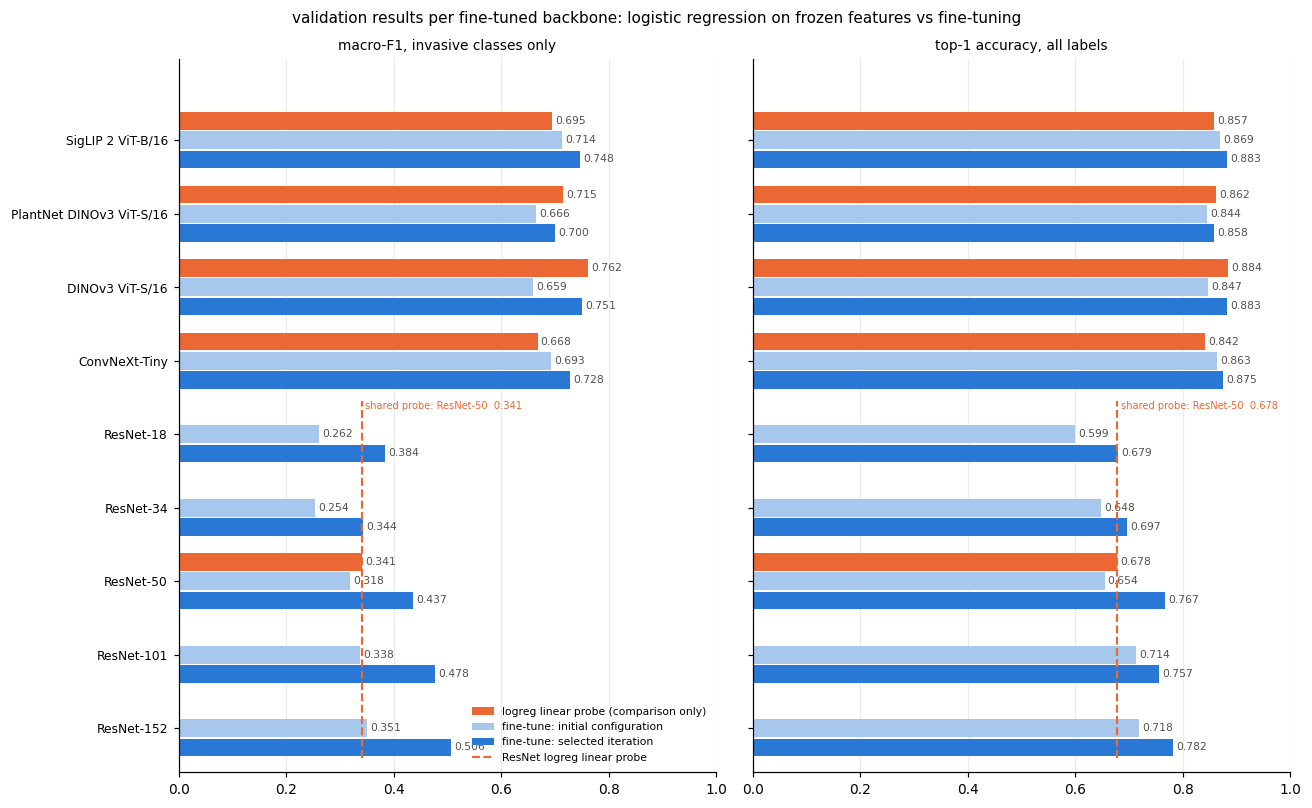

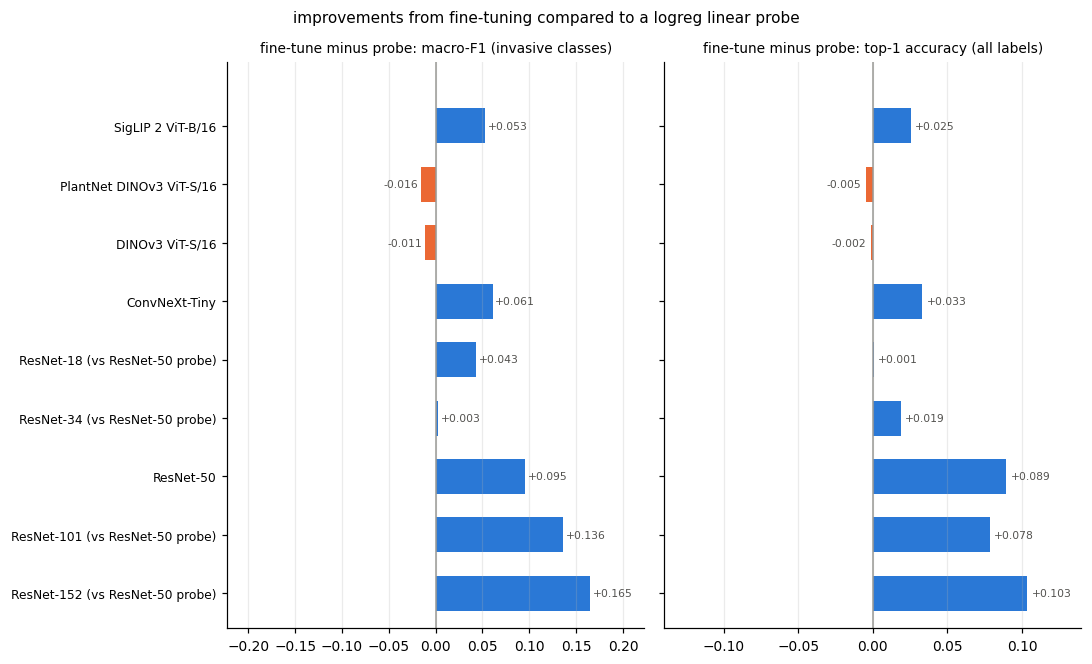

In [7]:
def series_blocks(index_series: pd.Series, ypos: np.ndarray):
    """(series key, y of the top row, y of the bottom row) per contiguous block of a table ordered by series."""
    blocks, prev = [], None
    for s, y in zip(index_series, ypos):
        if s != prev:
            blocks.append([s, y, y]); prev = s
        blocks[-1][2] = y
    return blocks


def draw_series_blocks(ax, blocks, label_x=0.995):
    """Separator lines between series blocks and the series label above each block (y in data units, x in axes fraction)."""
    for i, (s, y_top, y_bottom) in enumerate(blocks):
        if len(blocks) > 1:
            ax.text(label_x, y_top + 0.45, SERIES[s]["label"], transform=ax.get_yaxis_transform(), ha="right", va="bottom", fontsize=7, color=C_INK, style="italic")
        if i < len(blocks) - 1:
            ax.axhline(y_bottom - 0.5, color=C_GRAY, lw=0.8, ls="-", zorder=1)


def plot_probe_vs_finetune(cmp: pd.DataFrame, out_dir: Path):
    """Grouped horizontal bars per backbone: probe, fine-tune baseline, selected fine-tune. One panel per metric (no dual axis).
    A probe shared by several backbones (the ResNet-50 probe for all ResNets) is drawn once as a dashed line spanning the group.
    The fine-tuned series are separate blocks."""
    series = [("probe_f1", "probe_top1", "logreg linear probe (comparison only)", C_ORANGE), ("ft_baseline_f1", "ft_baseline_top1", "fine-tune: initial configuration", C_BLUE_LIGHT),
              ("ft_best_f1", "ft_best_top1", "fine-tune: selected iteration", C_BLUE)]
    n = len(cmp); h = 0.26; ypos = np.arange(n)[::-1]; row_y = dict(zip(cmp.index, ypos)); blocks = series_blocks(cmp["series"], ypos)
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.62 * n + 0.45 * len(blocks) + 1.4), sharey=True)
    for ax, mi, title in zip(axes, (0, 1), ("macro-F1, invasive classes only", "top-1 accuracy, all labels")):
        for j, (c_f1, c_top1, label, color) in enumerate(series):
            vals = cmp[c_f1 if mi == 0 else c_top1].to_numpy(dtype=float)
            if j == 0:
                vals = np.where(cmp["probe_shared"].to_numpy(), np.nan, vals)          # shared probes are drawn once, below
            y = ypos + (1 - j) * h
            ax.barh(y, np.nan_to_num(vals), height=h * 0.92, color=color, label=label)
            for yi, v in zip(y, vals):
                if np.isfinite(v):
                    ax.text(v + 0.006, yi, f"{v:.3f}", va="center", fontsize=7, color=C_INK)
        for g, sub in cmp[cmp["probe_shared"]].groupby("group"):
            members = cmp[cmp["group"] == g]; v = float(sub["probe_f1" if mi == 0 else "probe_top1"].iloc[0])
            if np.isfinite(v):
                ys = [row_y[name] for name in members.index]
                ax.plot([v, v], [min(ys) - 0.4, max(ys) + 0.45], color=C_ORANGE, ls="--", lw=1.4, zorder=4)
                ax.text(v + 0.006, max(ys) + 0.38, f"shared probe: {sub['probe_backbone'].iloc[0]}  {v:.3f}", fontsize=6.5, color=C_ORANGE, va="center")
        for yi, (name, r) in zip(ypos, cmp.iterrows()):
            if r["status"] == "not run":
                ax.text(0.01, yi, "not run yet", va="center", fontsize=7, color=C_GRAY, style="italic")
            elif r["status"] == "probe only" and r["probe_shared"]:
                ax.text(0.01, yi, "fine-tune not run yet", va="center", fontsize=7, color=C_GRAY, style="italic")
        draw_series_blocks(ax, blocks)
        ax.set_yticks(ypos); ax.set_yticklabels(cmp.index, fontsize=8); ax.set_xlim(0, 1.0); ax.set_ylim(-0.6, n - 0.4 + 0.5)
        ax.set_title(title, fontsize=9); ax.set_axisbelow(True); ax.grid(axis="y", visible=False)
    handles, labels = axes[0].get_legend_handles_labels()
    if cmp["probe_shared"].any():
        handles.append(Line2D([], [], color=C_ORANGE, ls="--", lw=1.4)); labels.append("ResNet logreg linear probe")
    axes[0].legend(handles, labels, fontsize=7, frameon=False, loc="lower right")
    fig.suptitle("validation results per fine-tuned backbone: logistic regression on frozen features vs fine-tuning", fontsize=10)
    fig.tight_layout(); fig.savefig(out_dir / "probe_vs_finetune.png", bbox_inches="tight"); plt.show()


def plot_gain(cmp: pd.DataFrame, out_dir: Path):
    """Gain of the selected fine-tune over its probe; diverging color around zero; one block per fine-tuned series."""
    sub = cmp[cmp["gain_f1"].notna()]
    if sub.empty:
        print("no backbone has both a probe and a fine-tune yet; skipping the gain plot"); return
    names = [f"{name} (vs {r['probe_backbone']} probe)" if r["probe_shared"] else name for name, r in sub.iterrows()]
    y = np.arange(len(sub))[::-1]; blocks = series_blocks(sub["series"], y)
    fig, axes = plt.subplots(1, 2, figsize=(10, 0.5 * len(sub) + 0.4 * len(blocks) + 1.2), sharey=True)
    for ax, col, title in zip(axes, ("gain_f1", "gain_top1"), ("macro-F1 (invasive classes)", "top-1 accuracy (all labels)")):
        v = sub[col].to_numpy()
        ax.barh(y, v, color=[C_BLUE if x >= 0 else C_ORANGE for x in v], height=0.6)
        for yi, x in zip(y, v):
            ax.text(x + (0.003 if x >= 0 else -0.003), yi, f"{x:+.3f}", va="center", ha="left" if x >= 0 else "right", fontsize=7, color=C_INK)
        ax.axvline(0, color=C_GRAY, lw=1); ax.set_yticks(y); ax.set_yticklabels(names, fontsize=8); ax.set_title(f"fine-tune minus probe: {title}", fontsize=9)
        lim = max(0.05, np.nanmax(np.abs(v)) * 1.35); ax.set_xlim(-lim, lim); ax.set_ylim(-0.6, len(sub) - 0.4 + 0.5); ax.grid(axis="y", visible=False)
        draw_series_blocks(ax, blocks)
    fig.suptitle("improvements from fine-tuning compared to a logreg linear probe", fontsize=10)
    fig.tight_layout(); fig.savefig(out_dir / "finetune_gain.png", bbox_inches="tight"); plt.show()


plot_probe_vs_finetune(comparison, OUT_DIR)
plot_gain(comparison, OUT_DIR)

## 5. Iteration trajectories of the fine-tuning notebooks

One panel per backbone group. Each backbone shows exactly the iterations recorded in its `decisions.json`, in name order, with the macro-F1 the decision record stores (the value of the run's `metrics_final.json` at decision time, so an iteration whose run folder was lost on Drive is still plotted): filled markers for accepted iterations, hollow for rejected, a ring around the selected iteration. The line follows the configuration the notebook converged on; the dashed orange line is the linear probe the group is compared with. Finished runs that have no entry in the log (for SigLIP 2, the runs after 04 that were trained on the baseline configuration) are not part of the trajectory and are listed under the figures instead.

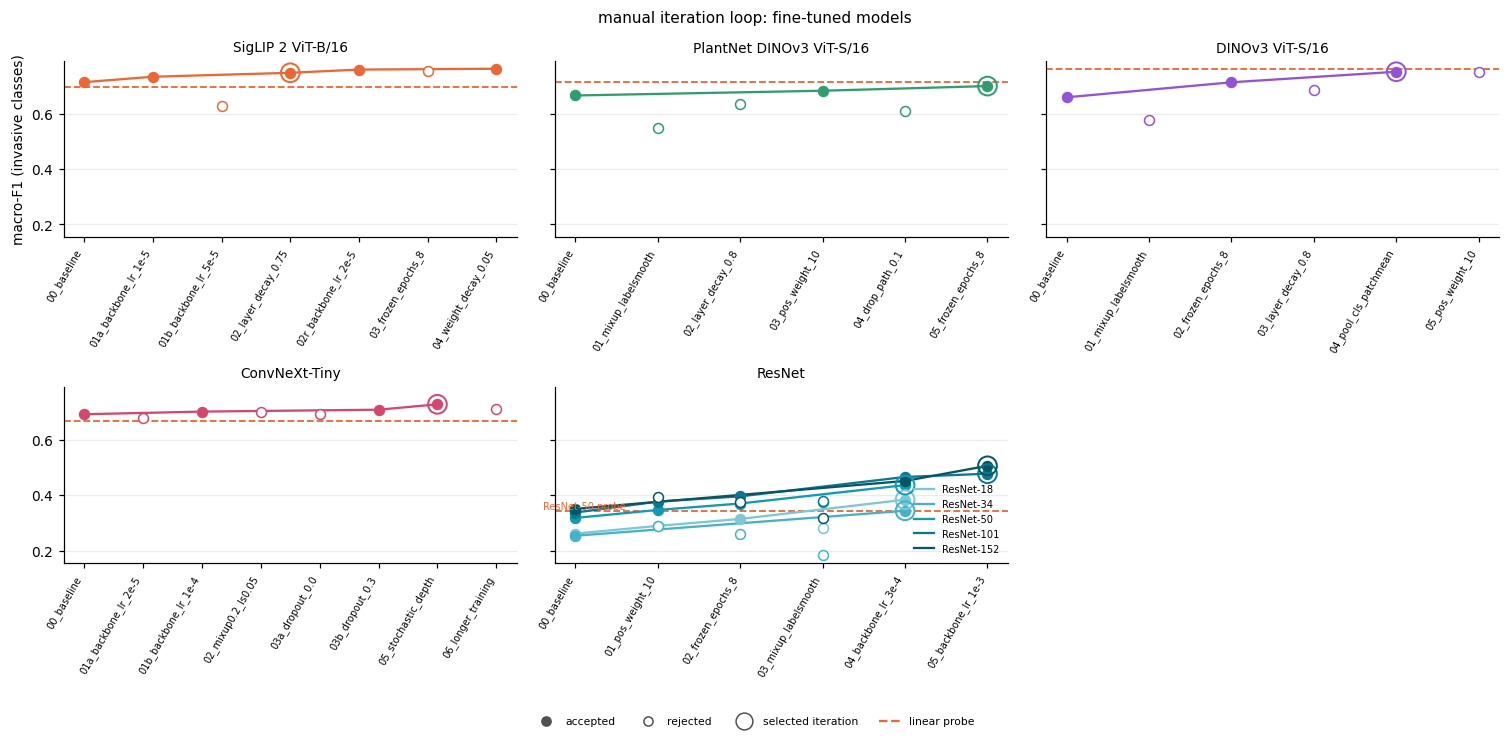

siglip2_base: finished runs with no entry in decisions.json, not plotted: ['05_drop_path_0.1', '06_mixup0.2_ls0.05', '07a_dropout_0']
siglip2_base: iterations in decisions.json whose run folder has no metrics_final.json, plotted from the decision record: ['02r_backbone_lr_2e-5', '03_frozen_epochs_8', '04_weight_decay_0.05']
  NOTE: the last accepted iteration of the log is 04_weight_decay_0.05, but its run folder is incomplete, so the selection uses the last accepted FINISHED run, 02_layer_decay_0.75 (0.7476)
convnext_tiny: finished runs with no entry in decisions.json, not plotted: ['04_weight_decay']


In [8]:
def logged_iterations(key) -> pd.DataFrame:
    """The iterations of a fine-tuning notebook as its decisions.json records them, in name order, with the metric stored there."""
    log = load_json(RUNS_DIR / key / "decisions.json") or []
    rows = [{"iteration": d["name"], "decision": d["decision"], SELECT_METRIC: d.get(SELECT_METRIC, np.nan)} for d in log]
    return pd.DataFrame(rows, columns=["iteration", "decision", SELECT_METRIC]).sort_values("iteration").reset_index(drop=True)


def plot_iteration_trajectories(series: str, out_dir: Path):
    keys_in = [k for k in FINETUNED_BACKBONES if BACKBONES[k]["series"] == series]
    panels = [(g, [k for k in keys_in if BACKBONES[k]["group"] == g and not logged_iterations(k).empty]) for g in GROUPS]
    panels = [(g, keys) for g, keys in panels if keys]
    if not panels:
        print(f"{SERIES[series]['label']}: no decisions.json with iterations yet"); return
    ncol = 2 if len(panels) == 4 else min(3, len(panels)); nrow = int(np.ceil(len(panels) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 3.3 * nrow), sharey=True, squeeze=False)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    for ax, (g, keys) in zip(axes.flat, panels):
        logs = {k: logged_iterations(k) for k in keys}
        its = sorted(set().union(*[set(l["iteration"]) for l in logs.values()])); xpos = {it: i for i, it in enumerate(its)}
        for key in keys:
            ft = logs[key]; color = BACKBONE_COLORS[key]
            x = ft["iteration"].map(xpos).to_numpy(); v = ft[SELECT_METRIC].to_numpy(dtype=float)
            acc = (ft["decision"] == "accepted").to_numpy(); rej = ~acc
            ax.plot(x[acc], v[acc], color=color, lw=1.5, zorder=2, label=BACKBONES[key]["display"] if len(keys) > 1 else None)
            ax.scatter(x[acc], v[acc], color=color, s=42, zorder=3)
            ax.scatter(x[rej], v[rej], facecolors="white", edgecolors=color, s=42, zorder=3)
            best = selected[key]["ft_best"]
            if best is not None and best["iteration"] in xpos:
                ax.scatter([xpos[best["iteration"]]], [best[SELECT_METRIC]], s=150, facecolors="none", edgecolors=color, linewidths=1.3, zorder=4)
        for pb in dict.fromkeys(PROBE_OF[k] for k in keys):
            probe = get_run(f"logreg_{pb}", "00_baseline")
            if probe is not None:
                ax.axhline(probe[SELECT_METRIC], color=C_ORANGE, ls="--", lw=1.2, zorder=1)
                if len(keys) > 1:                                                # name the shared probe; single panels have the figure legend
                    ax.text(-0.4, probe[SELECT_METRIC], f"{BACKBONES[pb]['display']} probe", fontsize=6.5, color=C_ORANGE, ha="left", va="bottom")
        ax.set_xticks(range(len(its))); ax.set_xticklabels(its, rotation=60, ha="right", fontsize=6.5)
        ax.set_title(g if len(keys) > 1 else BACKBONES[keys[0]]["display"], fontsize=9); ax.grid(axis="x", visible=False)
        if len(keys) > 1:
            ax.legend(fontsize=6.5, frameon=False, loc="lower right")
    axes.flat[0].set_ylabel("macro-F1 (invasive classes)")
    handles = [Line2D([], [], marker="o", color=C_INK, ls="", label="accepted"), Line2D([], [], marker="o", mfc="white", mec=C_INK, color=C_INK, ls="", label="rejected"),
               Line2D([], [], marker="o", mfc="none", mec=C_INK, ms=11, ls="", label="selected iteration"), Line2D([], [], color=C_ORANGE, ls="--", label="linear probe")]
    fig.legend(handles=handles, fontsize=7, frameon=False, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"manual iteration loop: {SERIES[series]['label']}", fontsize=10)
    fig.tight_layout(rect=(0, 0.04, 1, 1)); fig.savefig(out_dir / f"iteration_trajectories_{series}.png", bbox_inches="tight"); plt.show()


for s in FINETUNED_SERIES:
    plot_iteration_trajectories(s, OUT_DIR)
for key in FINETUNED_BACKBONES:
    log = logged_iterations(key)
    if log.empty:
        continue
    finished = set(finetune_runs(key)["iteration"])
    not_logged = sorted(finished - set(log["iteration"])); lost = [it for it in log["iteration"] if it not in finished]
    if not_logged:
        print(f"{key}: finished runs with no entry in decisions.json, not plotted: {not_logged}")
    if lost:
        print(f"{key}: iterations in decisions.json whose run folder has no metrics_final.json, plotted from the decision record: {lost}")
        last_acc = [it for it, d in zip(log["iteration"], log["decision"]) if d == "accepted"]
        best = selected[key]["ft_best"]
        if last_acc and best is not None and best["iteration"] != last_acc[-1]:
            print(f"  NOTE: the last accepted iteration of the log is {last_acc[-1]}, but its run folder is incomplete, so the selection uses "
                  f"the last accepted FINISHED run, {best['iteration']} ({best[SELECT_METRIC]:.4f})")

## 6. Training dynamics of the selected fine-tune runs

Validation macro-F1 per epoch from each selected run's `history.csv` (the per-epoch value is without TTA, so it is slightly below the final number in the tables). The dot marks the epoch whose checkpoint was kept; the dotted vertical line in the same color marks the end of that run's frozen stage. Backbones of one group share a color family (ResNets: lightest = smallest).

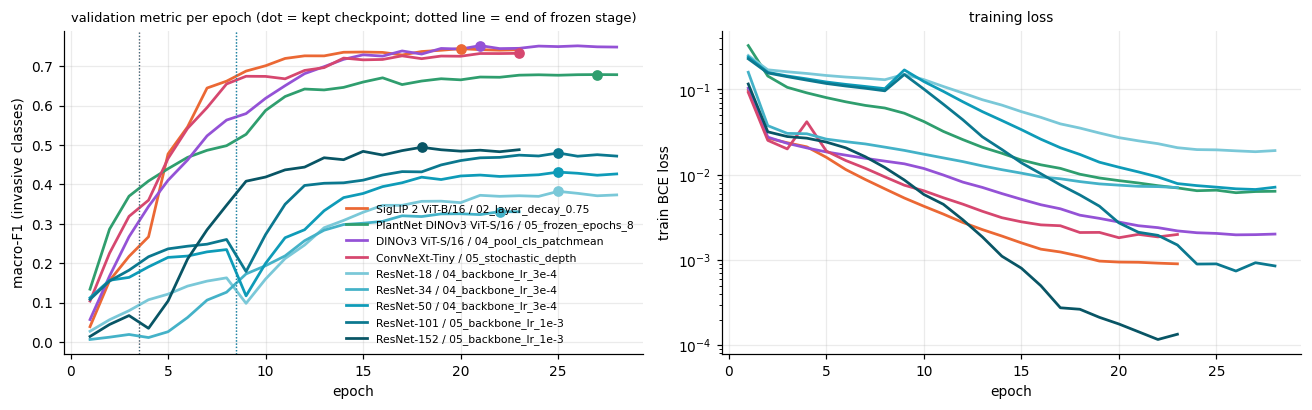

In [9]:
def plot_training_curves(out_dir: Path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    any_curve = False
    for key, sel in selected.items():
        best = sel["ft_best"]
        if best is None or not best["has_history"]:
            continue
        hist = pd.read_csv(RUNS_DIR / best["run_dir"] / "history.csv"); color = BACKBONE_COLORS[key]; any_curve = True
        label = f"{BACKBONES[key]['display']} / {best['iteration']}"
        for ax, col in zip(axes, (SELECT_METRIC, "train_loss")):
            ax.plot(hist["epoch"], hist[col], color=color, lw=1.8, label=label)
        if best["best_epoch"] is not None and not pd.isna(best["best_epoch"]):
            e = int(best["best_epoch"]); row = hist[hist["epoch"] == e]
            if len(row):
                axes[0].scatter([e], row[SELECT_METRIC], color=color, s=36, zorder=3)
        n_frozen = int(best["_config"].get("frozen_epochs", 0) or 0)
        if n_frozen:
            axes[0].axvline(n_frozen + 0.5, color=color, lw=0.8, ls=":", alpha=0.6)
    if not any_curve:
        plt.close(fig); print("no history.csv found for the selected fine-tune runs"); return
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("macro-F1 (invasive classes)"); axes[0].set_title("validation metric per epoch (dot = kept checkpoint; dotted line = end of frozen stage)", fontsize=8.5)
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("train BCE loss"); axes[1].set_yscale("log"); axes[1].set_title("training loss", fontsize=9)
    axes[0].legend(fontsize=7, frameon=False, loc="lower right")
    fig.tight_layout(); fig.savefig(out_dir / "training_curves_selected.png", bbox_inches="tight"); plt.show()


plot_training_curves(OUT_DIR)

## 7. BioCLIP 2 series: frozen-feature methods

This table lists each BioCLIP2 model variant with the hyperparameters its notebook chose on validation (`C` of the logistic regression, `k` of the kNN, the kNN weight `w_knn` of the combination, the vocabulary size of the zero-shot classifiers). These numbers come from different notebooks and rest on different assumptions (zero-shot vocabularies, a probe trained by SGD rather than the logreg sweep); the ring in the figure marks the configuration that goes to the test set (Section 8). The section runs for every series of `mode == "frozen"`.

In [10]:
def family_best(family):
    """Last accepted run of a family (decisions.json), else its highest-scoring run."""
    sub = runs[runs["family"] == family]
    if sub.empty:
        return None
    acc = sub[sub["decision"] == "accepted"].sort_values("decision_order")
    return acc.iloc[-1] if len(acc) else sub.loc[sub[SELECT_METRIC].idxmax()]


def short_label(r) -> str:
    """Compact name of a run for figure axes and table rows: '<backbone> | <iteration>' for a fine-tune, '<backbone> | probe' for a
    logreg_<key> baseline, '<backbone> | <method folder>[: <run>]' for every other family (bioclip2_zeroshot_full -> zeroshot_full)."""
    disp = BACKBONES[r["backbone"]]["display"] if r["backbone"] in BACKBONES else r["family"]
    if r["kind"] == "finetune":
        return f"{disp} | {r['iteration']}"
    if r["family"].startswith("logreg_"):
        return f"{disp} | probe"
    what = r["family"][len(r["backbone"]) + 1:] if r["backbone"] and r["family"].startswith(r["backbone"] + "_") else r["family"]
    return f"{disp} | {what}" + (f": {r['iteration']}" if r["iteration"] != "00_baseline" else "")


METHOD_FIELDS = ["method", "C", "k", "tau", "w_knn", "vocab_size", "prompt"]

frozen_rows = []
for s in FROZEN_SERIES:
    for fam in sorted(runs.loc[runs["series"] == s, "family"].unique()):
        r = family_best(fam); cfg = r["_config"]
        frozen_rows.append({"series": s, "family": fam, "candidate": r["candidate"], "short": short_label(r), "kind": r["kind"], "iteration": r["iteration"],
                            "decision": r["decision"], "n_runs": int((runs["family"] == fam).sum()),
                            **{f: (r["C"] if f == "C" else cfg.get(f, np.nan)) for f in METHOD_FIELDS},
                            **{k: r[k] for k in KEY_METRICS}, "train_minutes": r["train_minutes"], "weights_file": r["weights_file"]})
frozen_table = pd.DataFrame(frozen_rows)
if frozen_table.empty:
    print("no runs in a frozen-feature series yet (" + ", ".join(SERIES[s]["label"] for s in FROZEN_SERIES) + ")")
else:
    frozen_table = frozen_table.sort_values(["series", SELECT_METRIC, KPI_METRIC], ascending=[True, False, False]).reset_index(drop=True)
    frozen_table.to_csv(OUT_DIR / "frozen_series.csv", index=False)
    for s in FROZEN_SERIES:
        block = frozen_table[frozen_table["series"] == s]
        if block.empty:
            print(f"{SERIES[s]['label']}: nothing run yet"); continue
        print(f"=== {SERIES[s]['label']}: one run per family, ranked by {SELECT_METRIC} ===")
        display(blank(block.set_index("short")[["family", "kind", "iteration", "decision", "n_runs"] + METHOD_FIELDS + KEY_METRICS]))

=== BioCLIP 2 (frozen features, no fine-tuning): one run per family, ranked by macro_f1_invasive ===


,family,kind,iteration,decision,n_runs,method,C,k,tau,w_knn,vocab_size,prompt,macro_f1_invasive,top1_acc_all,macro_ap_invasive,top1_recall_invasive,top3_recall_invasive,bin_precision_invasive,bin_recall_invasive,bin_auroc_invasive,noninv_auroc,threshold
short,,,,,,,,,,,,,,,,,,,,,,
BioCLIP 2 ViT-L/14 | knn_zeroshot_full,bioclip2_knn_zeroshot_full,knn+zeroshot,00_baseline,accepted,1,knn+zero_shot,,5,0.05,0.25,4573,,0.9728,0.9854,0.9916,0.9776,0.9939,0.9836,0.9796,0.9985,0.9985,0.14
BioCLIP 2 ViT-L/14 | probe: species_textinit,bioclip2_probe,logreg,species_textinit,undecided,9,,,,,,,,0.9703,0.9848,0.9913,0.9745,0.9919,0.9927,0.9684,0.9986,0.9986,0.36
BioCLIP 2 ViT-L/14 | zeroshot: taxonomic,bioclip2_zeroshot,zeroshot,taxonomic,accepted,3,,,,,,,taxonomic,0.9678,0.983,0.9915,0.9735,0.9939,0.9916,0.9633,0.9985,0.9985,0.33
BioCLIP 2 ViT-L/14 | zeroshot_full,bioclip2_zeroshot_full,zeroshot,00_baseline,accepted,1,zero_shot,,,,,4573,scientific,0.9668,0.9823,0.9897,0.9756,0.9929,0.9815,0.9705,0.9983,0.9983,0.06
BioCLIP 2 ViT-L/14 | knn,bioclip2_knn,knn,00_baseline,accepted,1,knn,,5,0.05,,,,0.9635,0.9802,0.9751,0.9695,0.9817,0.9905,0.9552,0.9956,0.9956,0.53
BioCLIP 2 ViT-L/14 | probe,logreg_bioclip2,logreg,00_baseline,accepted,1,,0.3,,,,,,0.9511,0.9746,0.9772,0.9684,0.9878,0.982,0.945,0.9953,0.9953,0.14


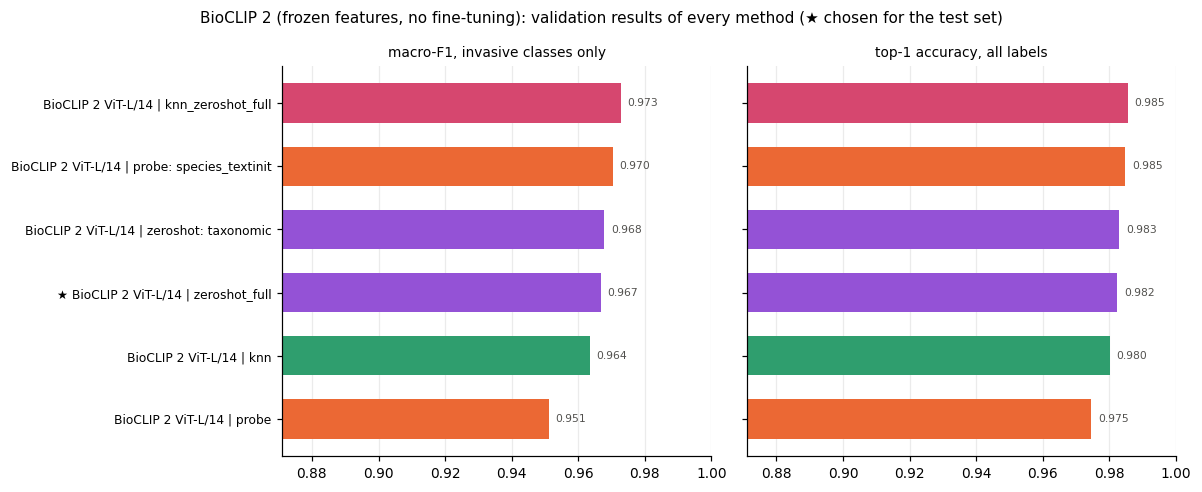

In [11]:
def plot_frozen_series(table: pd.DataFrame, s: str, chosen: str | None, out_dir: Path):
    """Horizontal bars of the two headline metrics for every family of a frozen series, colored by kind; a star in front of the name
    marks the run that goes to the test set."""
    sub = table[table["series"] == s]
    if sub.empty:
        return
    n = len(sub); y = np.arange(n)[::-1]
    names = [("★ " if c == chosen else "") + name for c, name in zip(sub["candidate"], sub["short"])]
    fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * n + 1.5), sharey=True)
    lo = max(0.0, float(sub[[SELECT_METRIC, KPI_METRIC]].min().min()) - 0.08)
    for ax, col, title in zip(axes, (SELECT_METRIC, KPI_METRIC), ("macro-F1, invasive classes only", "top-1 accuracy, all labels")):
        v = sub[col].to_numpy(dtype=float)
        ax.barh(y, v, color=[KIND_COLORS[k] for k in sub["kind"]], height=0.62, zorder=2)
        for yi, x in zip(y, v):
            ax.text(x + 0.002, yi, f"{x:.3f}", va="center", fontsize=7, color=C_INK)
        ax.set_yticks(y); ax.set_yticklabels(names, fontsize=8); ax.set_xlim(lo, min(1.0, float(sub[col].max()) + 0.05)); ax.set_title(title, fontsize=9)
        ax.set_axisbelow(True); ax.grid(axis="y", visible=False)
    fig.suptitle(f"{SERIES[s]['label']}: validation results of every method (★ chosen for the test set)", fontsize=10)
    fig.tight_layout(); fig.savefig(out_dir / f"{s}_methods.png", bbox_inches="tight"); plt.show()


for s in FROZEN_SERIES:
    if not frozen_table.empty:
        ranked = frozen_table[frozen_table["series"] == s]
        plot_frozen_series(frozen_table, s, SERIES[s]["override"] or (ranked["candidate"].iloc[0] if len(ranked) else None), OUT_DIR)


## 8. The two selected models and the shortlist

Per series, the **candidates** are the `ft_best` run of every backbone of a fine-tuned series or the one run per family of a frozen series (Section 7), ranked by the primary metric with top-1 accuracy as tie-break. The model selected from a series is the top-ranked candidate unless `SERIES[...]["override"]` names another finished run of that series; the rule's pick is still reported next to it. The **shortlist** that Sections 9 to 12 examine holds, per series, the selected model and the `TOP_K_PER_SERIES` best candidates.

In [12]:
def series_candidates(s: str) -> pd.DataFrame:
    if SERIES[s]["mode"] == "finetune":
        rows = [selected[k]["ft_best"] for k in FINETUNED_BACKBONES if BACKBONES[k]["series"] == s and selected[k]["ft_best"] is not None]
    else:
        rows = [family_best(f) for f in sorted(runs.loc[runs["series"] == s, "family"].unique())]
    if not rows:
        return pd.DataFrame()
    return pd.DataFrame(rows).sort_values([SELECT_METRIC, KPI_METRIC], ascending=False).reset_index(drop=True)


def pick_series(s: str):
    """(selected model row or None, how it was chosen, the rule's pick, the ranked candidates)."""
    cands = series_candidates(s)
    by_rule = cands.iloc[0] if len(cands) else None
    rule = f"highest {SELECT_METRIC} among the candidates of the series (tie-break {KPI_METRIC})"
    ov = SERIES[s]["override"]
    if ov:
        hit = runs[runs["candidate"] == ov]
        assert len(hit), f"SERIES[{s!r}]['override'] = {ov!r} is not a finished run under {RUNS_DIR}"
        r = hit.iloc[0]
        assert r["series"] == s, f"SERIES[{s!r}]['override'] = {ov!r} belongs to series {r['series']!r}"
        if ov not in set(cands["candidate"]):
            print(f"NOTE: the override {ov} of series {s!r} is not one of the series' candidates (not the run its family or notebook converged on); "
                  "using it anyway and adding it to the candidates")
            cands = pd.concat([cands, hit]).sort_values([SELECT_METRIC, KPI_METRIC], ascending=False).reset_index(drop=True)
        return r, f"SERIES[{s!r}]['override']", by_rule, cands
    return by_rule, rule, by_rule, cands


selected_models = {s: dict(zip(("run", "rule", "by_rule", "candidates"), pick_series(s))) for s in SERIES}
assert any(f["run"] is not None for f in selected_models.values()), "no finished run in any series: run at least one experiment notebook first"

rows = []
for s, f in selected_models.items():
    r = f["run"]
    if r is None:
        rows.append({"series": s, "label": SERIES[s]["label"], "selected": "(nothing run yet)"}); continue
    rows.append({"series": s, "label": SERIES[s]["label"], "selected": r["candidate"], "short": short_label(r), "kind": r["kind"], "decision": r["decision"],
                 **{k: r[k] for k in KEY_METRICS}, "chosen_by": f["rule"],
                 "rule_pick": f["by_rule"]["candidate"] if f["by_rule"] is not None else "", "n_candidates": len(f["candidates"]),
                 "test_protocol": ("fixed configuration, scored once on the test set without fine-tuning" if SERIES[s]["mode"] == "frozen"
                                   else "fine-tuned on the full training set with this configuration, then scored on the test set")})
selected_model_table = pd.DataFrame(rows).set_index("series")
selected_model_table.to_csv(OUT_DIR / "selected_models.csv")
print("the two models that go to the test set:")
display(blank(selected_model_table[["label", "selected", "kind", "decision", SELECT_METRIC, KPI_METRIC, "threshold", "chosen_by", "rule_pick", "n_candidates"]]))
for s, f in selected_models.items():
    if f["run"] is not None and f["by_rule"] is not None and f["run"]["candidate"] != f["by_rule"]["candidate"]:
        print(f"{SERIES[s]['label']}: the override {f['run']['candidate']} ({f['run'][SELECT_METRIC]:.4f}) replaces the rule's pick "
              f"{f['by_rule']['candidate']} ({f['by_rule'][SELECT_METRIC]:.4f}). Reason: {SERIES[s]['note'] or '(no note in SERIES)'}")

cand_frames = []
for s, f in selected_models.items():
    cands = f["candidates"]
    if cands.empty:
        continue
    cands = cands.copy(); cands["series_rank"] = np.arange(1, len(cands) + 1); cands["selected"] = cands["candidate"] == f["run"]["candidate"]
    cand_frames.append(cands)
series_candidates_table = pd.concat(cand_frames, ignore_index=True)
series_candidates_table["short"] = [short_label(r) for _, r in series_candidates_table.iterrows()]
series_candidates_table.drop(columns=["_config", "_metrics"]).to_csv(OUT_DIR / "series_candidates.csv", index=False)
print(f"\ncandidates per series, ranked by {SELECT_METRIC} (tie-break {KPI_METRIC}); * = selected:")
show = series_candidates_table.copy(); show["short"] = np.where(show["selected"], "* " + show["short"], "  " + show["short"])
display(blank(show.set_index(["series", "series_rank"])[["short", "candidate", "kind", "decision"] + KEY_METRICS + ["train_minutes"]]))

shortlist = series_candidates_table[(series_candidates_table["series_rank"] <= TOP_K_PER_SERIES) | series_candidates_table["selected"]].reset_index(drop=True)
shortlist.drop(columns=["_config", "_metrics"]).to_csv(OUT_DIR / "shortlist.csv", index=False)
print(f"\nshortlist for Sections 9 to 12: {len(shortlist)} runs (" + ", ".join(f"{int((shortlist['series'] == s).sum())} {SERIES[s]['label']}" for s in SERIES) + ")")

the two models that go to the test set:


,label,selected,kind,decision,macro_f1_invasive,top1_acc_all,threshold,chosen_by,rule_pick,n_candidates
series,,,,,,,,,,
bioclip2,"BioCLIP 2 (frozen features, no fine-tuning)",bioclip2_zeroshot_full/00_baseline,zeroshot,accepted,0.9668,0.9823,0.06,SERIES['bioclip2']['override'],bioclip2_knn_zeroshot_full/00_baseline,6
finetune,fine-tuned models,dinov3_vits16/04_pool_cls_patchmean,finetune,accepted,0.7514,0.8826,0.14,SERIES['finetune']['override'],dinov3_vits16/04_pool_cls_patchmean,9


BioCLIP 2 (frozen features, no fine-tuning): the override bioclip2_zeroshot_full/00_baseline (0.9668) replaces the rule's pick bioclip2_knn_zeroshot_full/00_baseline (0.9728). Reason: The rule picks bioclip2_knn_zeroshot_full (val macro-F1 0.973), which ties with bioclip2_zeroshot_full (0.967; 95% interval of the paired difference -0.014 to +0.002). In the unknown-species rehearsal of notebook 06 (species hidden from the model on val) the kNN + zero-shot combination flags 10-15% of the unknown-species photos as invasive against about 4% for zero-shot-full, so zero-shot-full is the better model for the test set.

candidates per series, ranked by macro_f1_invasive (tie-break top1_acc_all); * = selected:


short                                candidate          kind   decision macro_f1_invasive top1_acc_all macro_ap_invasive  \
series   series_rank                                                                                                                                                                       
bioclip2 1                     BioCLIP 2 ViT-L/14 | knn_zeroshot_full   bioclip2_knn_zeroshot_full/00_baseline  knn+zeroshot   accepted            0.9728       0.9854            0.9916   
         2               BioCLIP 2 ViT-L/14 | probe: species_textinit          bioclip2_probe/species_textinit        logreg  undecided            0.9703       0.9848            0.9913   
         3                   BioCLIP 2 ViT-L/14 | zeroshot: taxonomic              bioclip2_zeroshot/taxonomic      zeroshot   accepted            0.9678        0.983            0.9915   
         4                       * BioCLIP 2 ViT-L/14 | zeroshot_full       bioclip2_zeroshot_full/00_baseline      zeroshot   accepted            0.9668       0.9823            0.9897   
         5                                   BioCLIP 2 ViT-L/14 | knn                 bioclip2_knn/00_baseline           knn   accepted            0.9635       0.9802            0.9751   
         6                                 BioCLIP 2 ViT-L/14 | probe              logreg_bioclip2/00_baseline        logreg   accepted            0.9511       0.9746            0.9772   
finetune 1                  * DINOv3 ViT-S/16 | 04_pool_cls_patchmean      dinov3_vits16/04_pool_cls_patchmean      finetune   accepted            0.7514       0.8826             0.782   
         2                    SigLIP 2 ViT-B/16 | 02_layer_decay_0.75         siglip2_base/02_layer_decay_0.75      finetune   accepted            0.7476       0.8826            0.7908   
         3                        ConvNeXt-Tiny | 05_stochastic_depth        convnext_tiny/05_stochastic_depth      finetune   accepted            0.7285       0.8748             0.771   
         4              PlantNet DINOv3 ViT-S/16 | 05_frozen_epochs_8  plantnet_dinov3_vits/05_frozen_epochs_8      finetune   accepted            0.6997       0.8578            0.7254   
         5                           ResNet-152 | 05_backbone_lr_1e-3            resnet152/05_backbone_lr_1e-3      finetune   accepted            0.5063       0.7816            0.5093   
         6                           ResNet-101 | 05_backbone_lr_1e-3            resnet101/05_backbone_lr_1e-3      finetune   accepted            0.4778       0.7565            0.4832   
         7                            ResNet-50 | 04_backbone_lr_3e-4             resnet50/04_backbone_lr_3e-4      finetune   accepted            0.4366       0.7673             0.443   
         8                            ResNet-18 | 04_backbone_lr_3e-4             resnet18/04_backbone_lr_3e-4      finetune   accepted            0.3841       0.6787             0.379   
         9                            ResNet-34 | 04_backbone_lr_3e-4             resnet34/04_backbone_lr_3e-4      finetune   accepted            0.3439       0.6967            0.3302   

                     top1_recall_invasive top3_recall_invasive bin_precision_invasive bin_recall_invasive bin_auroc_invasive noninv_auroc threshold train_minutes  
series   series_rank                                                                                                                                               
bioclip2 1                         0.9776               0.9939                 0.9836              0.9796             0.9985       0.9985      0.14       18.5227  
         2                         0.9745               0.9919                 0.9927              0.9684             0.9986       0.9986      0.36                
         3                         0.9735               0.9939                 0.9916              0.9633             0.9985       0.9985      0.33           0.0  
         4                         0.9756      


shortlist for Sections 9 to 12: 8 runs (4 BioCLIP 2 (frozen features, no fine-tuning), 4 fine-tuned models)


## 9. All runs at a glance

Every finished run on the two headline metrics. Color is the kind of run, marker is the series (triangle BioCLIP 2, diamond the fine-tuned backbones; crosses are families built on no registered backbone). The labeled points are the two selected models (black edge, bold label) and the linear probes the fine-tuned backbones are compared with.

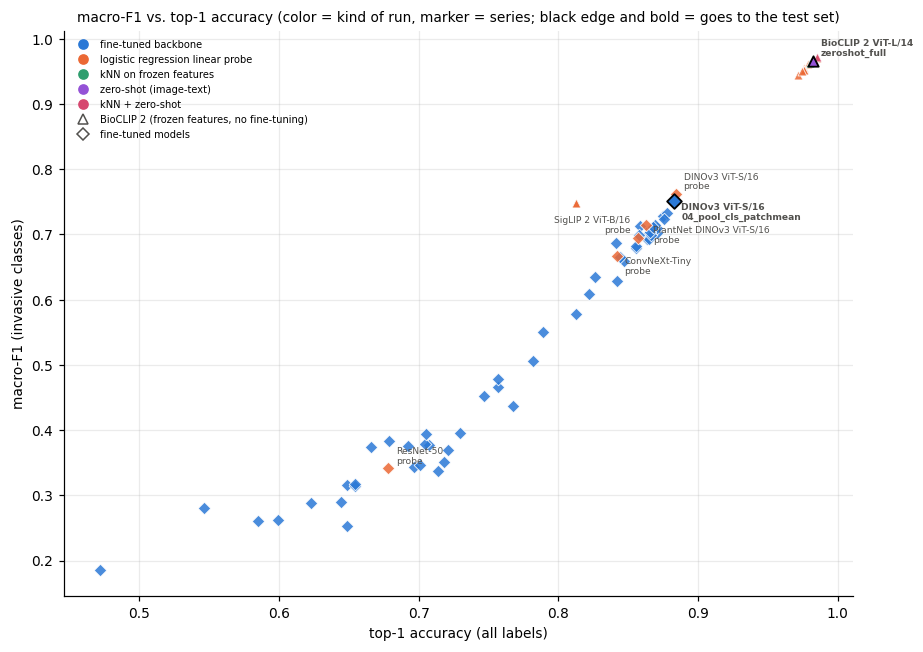

In [13]:
def place_labels(ax, fig, items, fontsize=6):
    """Annotate (x, y, text[, bold]) points, trying a few offsets per label and keeping the first that overlaps no earlier label."""
    fig.canvas.draw(); renderer = fig.canvas.get_renderer(); placed = []
    offsets = [(5, 3), (5, -12), (-5, 3), (-5, -12), (5, 14), (-5, 14), (5, -24), (-5, -24)]
    for item in sorted(items, key=lambda t: (-t[1], t[0])):
        x, y, txt = item[:3]; weight = "bold" if len(item) > 3 and item[3] else "normal"
        for dx, dy in offsets:
            t = ax.annotate(txt, (x, y), textcoords="offset points", xytext=(dx, dy), fontsize=fontsize, fontweight=weight, color=C_INK, ha="left" if dx > 0 else "right")
            bb = t.get_window_extent(renderer)
            if not any(bb.overlaps(b) for b in placed):
                placed.append(bb); break
            t.remove()
        else:
            t = ax.annotate(txt, (x, y), textcoords="offset points", xytext=offsets[0], fontsize=fontsize, fontweight=weight, color=C_INK); placed.append(t.get_window_extent(renderer))


def plot_all_runs(out_dir: Path):
    """Every finished run; labels only on the two runs that go to the test set (black edge, bold label) and on the logreg baselines the fine-tuned
    backbones are compared with (a probe shared by several backbones is labeled once)."""
    fig, ax = plt.subplots(figsize=(8.5, 6))
    for s in list(SERIES) + [None]:
        marker = SERIES_MARKERS.get(s, "x")
        for kind in KIND_COLORS:
            sub = runs[(runs["kind"] == kind) & ((runs["series"] == s) if s else runs["series"].isna())]
            if sub.empty:
                continue
            edge = {} if marker == "x" else {"edgecolors": "white", "linewidths": 0.6}
            ax.scatter(sub[KPI_METRIC], sub[SELECT_METRIC], color=KIND_COLORS[kind], s=34, alpha=0.85, marker=marker, zorder=3, **edge)
    labeled, seen = [], set()
    for s, f in selected_models.items():
        r = f["run"]
        if r is not None:                                                           # the chosen runs: black edge on the marker, bold label
            ax.scatter([r[KPI_METRIC]], [r[SELECT_METRIC]], color=KIND_COLORS[r["kind"]], s=46, marker=SERIES_MARKERS.get(s, "x"),
                       edgecolors="black", linewidths=1.2, zorder=5)
            labeled.append((r[KPI_METRIC], r[SELECT_METRIC], short_label(r).replace(" | ", "\n"), True)); seen.add(r["candidate"])
    for key, sel in selected.items():
        r = sel["probe"]
        if r is not None and r["candidate"] not in seen:
            labeled.append((r[KPI_METRIC], r[SELECT_METRIC], short_label(r).replace(" | ", "\n"))); seen.add(r["candidate"])
    place_labels(ax, fig, labeled)
    kinds_present = [k for k in KIND_COLORS if (runs["kind"] == k).any()]
    handles = [Line2D([], [], marker="o", ls="", color=KIND_COLORS[k], label=KIND_LABELS[k]) for k in kinds_present]
    handles += [Line2D([], [], marker=SERIES_MARKERS[s], ls="", color=C_INK, mfc="none", label=SERIES[s]["label"]) for s in SERIES if (runs["series"] == s).any()]
    if runs["series"].isna().any():
        handles.append(Line2D([], [], marker="x", ls="", color=C_INK, label="no registered backbone"))
    ax.set_xlabel("top-1 accuracy (all labels)"); ax.set_ylabel("macro-F1 (invasive classes)")
    ax.set_title("macro-F1 vs. top-1 accuracy (color = kind of run, marker = series; black edge and bold = goes to the test set)", fontsize=9)
    ax.legend(handles=handles, fontsize=6.5, frameon=False, loc="upper left")
    fig.tight_layout(); fig.savefig(out_dir / "all_runs_scatter.png", bbox_inches="tight"); plt.show()


plot_all_runs(OUT_DIR)

## 10. Per-class results of the shortlist

The per-class heatmap shows the validation F1 of each class for every run on the shortlist (columns in series order, selected models marked with `*`), classes sorted by their mean F1, so the hardest species are at the top. The BioCLIP 2 columns are expected to be near 1 everywhere; the interesting differences are between the fine-tuned columns.

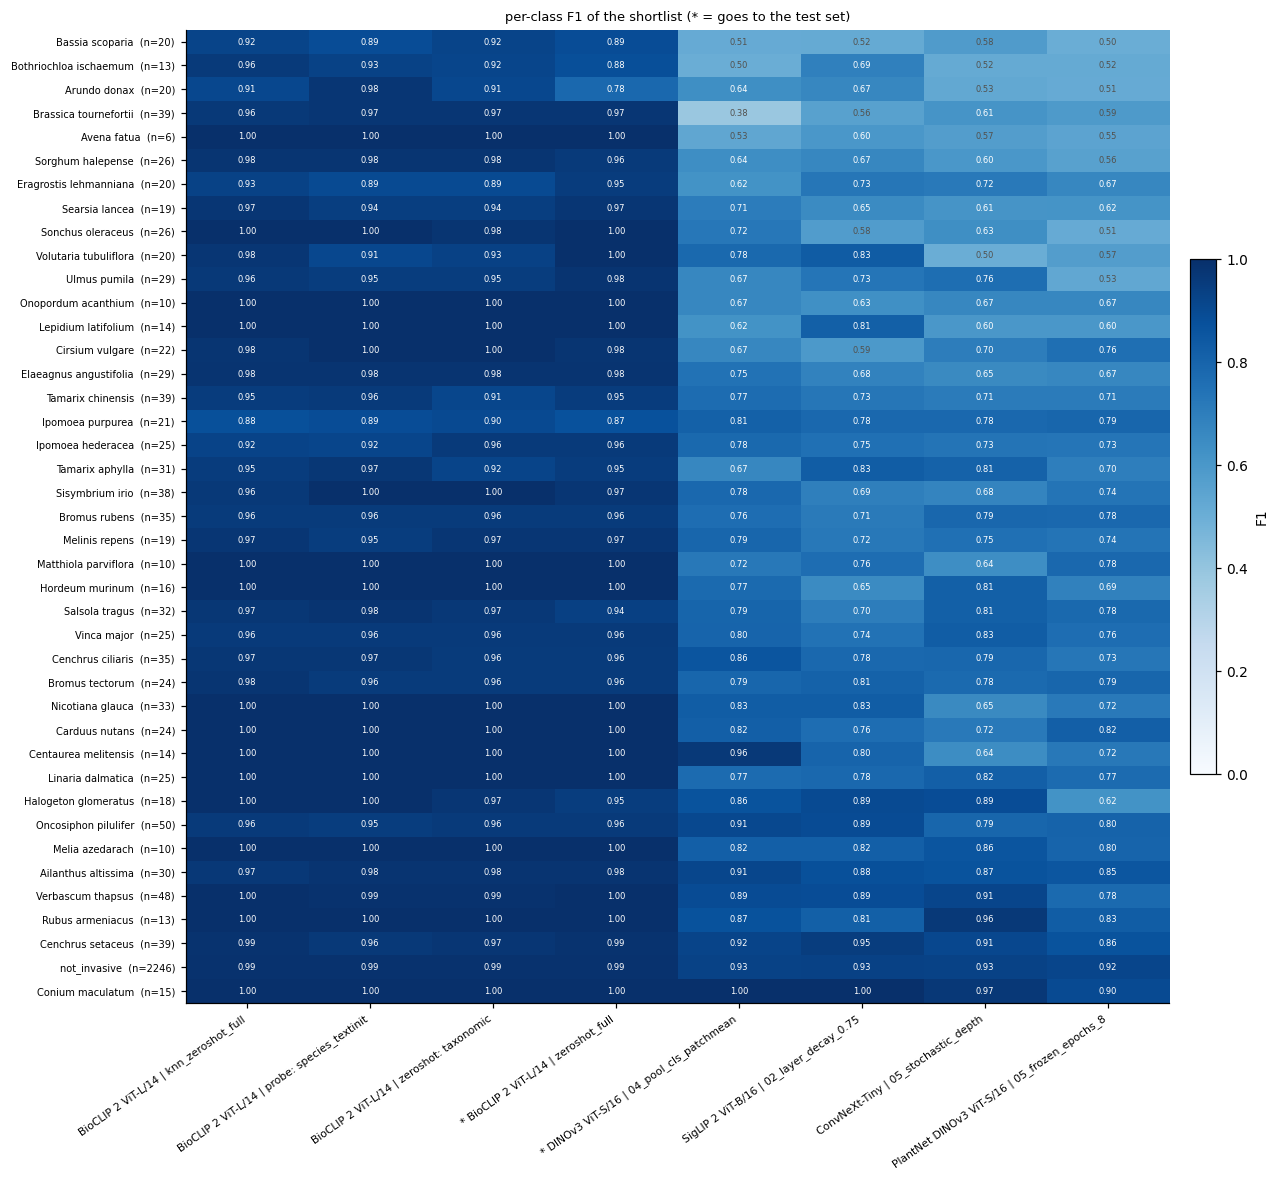

hardest classes (lowest mean F1 over the shortlist):


,val_support,mean_f1,best_run
Bassia scoparia,20,0.7161,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Bothriochloa ischaemum,13,0.7387,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Arundo donax,20,0.74,BioCLIP 2 ViT-L/14 | probe: species_textinit
Brassica tournefortii,39,0.7531,BioCLIP 2 ViT-L/14 | zeroshot: taxonomic
Avena fatua,6,0.7813,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Sorghum halepense,26,0.7952,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Eragrostis lehmanniana,20,0.7997,* BioCLIP 2 ViT-L/14 | zeroshot_full
Searsia lancea,19,0.8024,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Sonchus oleraceus,26,0.8036,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Volutaria tubuliflora,20,0.8117,* BioCLIP 2 ViT-L/14 | zeroshot_full


easiest classes:


,val_support,mean_f1,best_run
Conium maculatum,15,0.983,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
not_invasive,2246,0.9586,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Cenchrus setaceus,39,0.9435,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Rubus armeniacus,13,0.9344,BioCLIP 2 ViT-L/14 | knn_zeroshot_full
Verbascum thapsus,48,0.9313,BioCLIP 2 ViT-L/14 | knn_zeroshot_full


In [14]:
def per_class_table(cands: pd.DataFrame) -> pd.DataFrame:
    cols = {}
    for _, r in cands.iterrows():
        pcf = r["_metrics"].get("per_class_f1")
        if isinstance(pcf, dict):
            cols[("* " if r["selected"] else "") + r["short"]] = pd.Series(pcf, dtype=float)
    return pd.DataFrame(cols)


def val_support() -> pd.Series:
    """Validation rows per label, from any run's val_predictions.csv (every run scores the same val.csv)."""
    for _, r in runs.iterrows():
        if r["has_predictions"]:
            return pd.read_csv(RUNS_DIR / r["run_dir"] / "val_predictions.csv")["label"].value_counts()
    return pd.Series(dtype=int)


def plot_per_class_heatmap(pc: pd.DataFrame, support: pd.Series, out_dir: Path):
    order = pc.mean(axis=1).sort_values().index
    pc = pc.loc[order]
    fig, ax = plt.subplots(figsize=(0.9 * pc.shape[1] + 4.5, 0.21 * pc.shape[0] + 2.2))
    im = ax.imshow(pc.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(pc.shape[1])); ax.set_xticklabels(pc.columns, rotation=35, ha="right", fontsize=7)
    ax.set_yticks(range(pc.shape[0])); ax.set_yticklabels([f"{c}  (n={int(support.get(c, 0))})" for c in pc.index], fontsize=6.5)
    for i in range(pc.shape[0]):
        for j in range(pc.shape[1]):
            v = pc.iat[i, j]
            if np.isfinite(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=5.5, color="white" if v > 0.6 else C_INK)
    ax.grid(False); ax.set_title("per-class F1 of the shortlist (* = goes to the test set)", fontsize=8.5)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="F1")
    fig.tight_layout(); fig.savefig(out_dir / "per_class_f1_heatmap.png", bbox_inches="tight"); plt.show()


per_class = per_class_table(shortlist)
support = val_support()
if per_class.empty:
    print("no per_class_f1 in the shortlist's metrics_final.json")
else:
    plot_per_class_heatmap(per_class, support, OUT_DIR)
    pc_out = per_class.copy(); pc_out.insert(0, "val_support", support.reindex(pc_out.index).fillna(0).astype(int))
    pc_out["mean_f1"] = per_class.mean(axis=1); pc_out["best_run"] = per_class.idxmax(axis=1)
    pc_out.sort_values("mean_f1").to_csv(OUT_DIR / "per_class_f1.csv")
    print("hardest classes (lowest mean F1 over the shortlist):")
    display(blank(pc_out.sort_values("mean_f1").head(10)[["val_support", "mean_f1", "best_run"]]))
    print("easiest classes:")
    display(blank(pc_out.sort_values("mean_f1", ascending=False).head(5)[["val_support", "mean_f1", "best_run"]]))

## 11. Error analysis

`val_predictions.csv` carries the dataset's `group` (`invasive`, `native_background`, `introduced_unlisted`, `listed_not_invasive`, `native_listed`). For the shortlist: the share of each `not_invasive` group that is correctly left unflagged, the share of invasive rows that gets the right species, and the share of invasive rows flagged as invasive at all (any species). The agreement matrix shows how often two runs make the same 41-way prediction and how often at least one of the two is right.

,invasive: correct species,invasive: flagged (any species),introduced_unlisted: left unflagged (n=240),listed_not_invasive: left unflagged (n=193),native_background: left unflagged (n=1715),native_listed: left unflagged (n=98)
run,,,,,,
BioCLIP 2 ViT-L/14 | knn_zeroshot_full,0.9684,0.9796,0.9833,0.9896,0.9959,0.9694
BioCLIP 2 ViT-L/14 | probe: species_textinit,0.9572,0.9684,0.9917,0.9948,0.9983,0.9898
BioCLIP 2 ViT-L/14 | zeroshot: taxonomic,0.9521,0.9633,0.9958,0.9948,0.9988,0.9592
* BioCLIP 2 ViT-L/14 | zeroshot_full,0.9603,0.9705,0.9792,1.0,0.9988,0.8878
* DINOv3 ViT-S/16 | 04_pool_cls_patchmean,0.721,0.7749,0.8875,0.9585,0.9685,0.8367
SigLIP 2 ViT-B/16 | 02_layer_decay_0.75,0.72,0.7912,0.8708,0.9741,0.9679,0.8673
ConvNeXt-Tiny | 05_stochastic_depth,0.7006,0.7719,0.9,0.9534,0.9638,0.8469
PlantNet DINOv3 ViT-S/16 | 05_frozen_epochs_8,0.667,0.7393,0.8875,0.9948,0.9516,0.7857


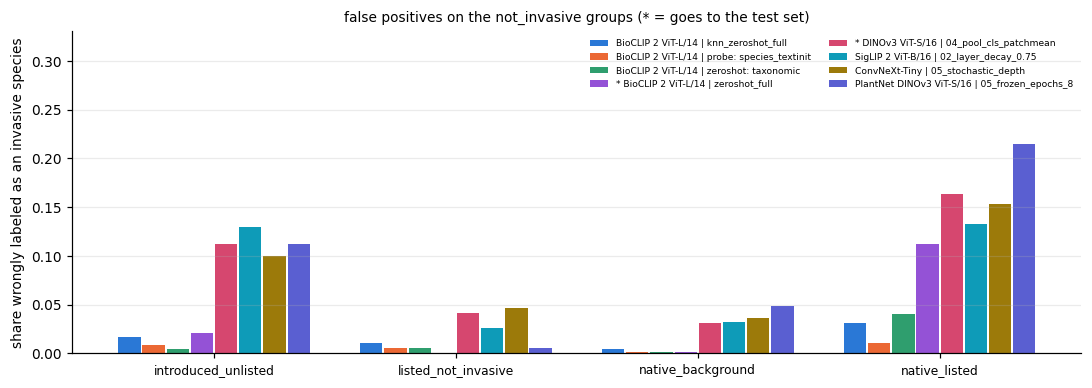


share of identical 41-way predictions (lower triangle) and top-1 accuracy of the pair (upper triangle):


,BioCLIP 2 ViT-L/14 | knn_zeroshot_full,BioCLIP 2 ViT-L/14 | probe: species_textinit,BioCLIP 2 ViT-L/14 | zeroshot: taxonomic,* BioCLIP 2 ViT-L/14 | zeroshot_full,* DINOv3 ViT-S/16 | 04_pool_cls_patchmean,SigLIP 2 ViT-B/16 | 02_layer_decay_0.75,ConvNeXt-Tiny | 05_stochastic_depth,PlantNet DINOv3 ViT-S/16 | 05_frozen_epochs_8
BioCLIP 2 ViT-L/14 | knn_zeroshot_full,,0.9919,0.9904,0.9888,0.9898,0.991,0.9895,0.9892
BioCLIP 2 ViT-L/14 | probe: species_textinit,0.9851,,0.9876,0.9916,0.9892,0.9901,0.9873,0.9882
BioCLIP 2 ViT-L/14 | zeroshot: taxonomic,0.987,0.9913,,0.9888,0.9885,0.9898,0.9873,0.9876
* BioCLIP 2 ViT-L/14 | zeroshot_full,0.9895,0.983,0.9873,,0.9888,0.9904,0.9876,0.9867
* DINOv3 ViT-S/16 | 04_pool_cls_patchmean,0.8848,0.8866,0.8854,0.8844,,0.9294,0.9241,0.921
SigLIP 2 ViT-B/16 | 02_layer_decay_0.75,0.8823,0.8848,0.8832,0.8817,0.8925,,0.9284,0.9275
ConvNeXt-Tiny | 05_stochastic_depth,0.8783,0.881,0.8792,0.8789,0.8931,0.8857,,0.9195
PlantNet DINOv3 ViT-S/16 | 05_frozen_epochs_8,0.8618,0.8643,0.8628,0.8634,0.8826,0.8702,0.8752,


In [15]:
def load_predictions(r) -> pd.DataFrame | None:
    f = RUNS_DIR / r["run_dir"] / "val_predictions.csv"
    return pd.read_csv(f) if f.exists() else None


preds = {("* " if r["selected"] else "") + r["short"]: load_predictions(r) for _, r in shortlist.iterrows()}
preds = {k: v for k, v in preds.items() if v is not None}
if not preds:
    print("no val_predictions.csv for the shortlist")
else:
    rows = []
    for name, p in preds.items():
        row = {"run": name}
        inv = p[p["label"] != NONE_LABEL]
        row["invasive: correct species"] = float((inv["pred"] == inv["label"]).mean())
        row["invasive: flagged (any species)"] = float((inv["pred"] != NONE_LABEL).mean())
        for g, sub in p[p["label"] == NONE_LABEL].groupby("group"):
            row[f"{g}: left unflagged (n={len(sub)})"] = float((sub["pred"] == NONE_LABEL).mean())
        rows.append(row)
    groups_tbl = pd.DataFrame(rows).set_index("run")
    groups_tbl.to_csv(OUT_DIR / "group_breakdown.csv")
    display(blank(groups_tbl))

    # false-positive rate per not_invasive group, one bar per run (fixed color per shortlist position); only the "left unflagged" columns
    # are groups (the two "invasive:" columns are the species accuracy and the detection rate of the invasive rows, not groups)
    gcols = [c for c in groups_tbl.columns if ": left unflagged (n=" in c]
    fig, ax = plt.subplots(figsize=(10, 3.6))
    w = 0.8 / len(groups_tbl); x = np.arange(len(gcols))
    palette = SERIES_COLORS + [shade(c, 0.4) for c in SERIES_COLORS]
    for i, (name, r) in enumerate(groups_tbl.iterrows()):
        ax.bar(x + (i - len(groups_tbl) / 2 + 0.5) * w, 1 - r[gcols].to_numpy(dtype=float), width=w * 0.92, color=palette[i % len(palette)], label=name)
    ax.set_xticks(x); ax.set_xticklabels([c.split(":")[0] for c in gcols], fontsize=8); ax.set_ylabel("share wrongly labeled as an invasive species")
    ax.set_ylim(0, min(1.0, float((1 - groups_tbl[gcols].to_numpy(dtype=float)).max()) * 1.45 + 0.02))      # headroom for the legend
    ax.set_title("false positives on the not_invasive groups (* = goes to the test set)", fontsize=9); ax.legend(fontsize=6, frameon=False, ncol=2); ax.grid(axis="x", visible=False)
    fig.tight_layout(); fig.savefig(OUT_DIR / "false_positives_by_group.png", bbox_inches="tight"); plt.show()

    names = list(preds); base = next(iter(preds.values()))
    agree = pd.DataFrame(index=names, columns=names, dtype=float); oracle = agree.copy()
    y_true = base["label"].to_numpy()
    for a in names:
        pa = preds[a].set_index("observation_id").loc[base["observation_id"], "pred"].to_numpy()
        for b in names:
            pb = preds[b].set_index("observation_id").loc[base["observation_id"], "pred"].to_numpy()
            agree.loc[a, b] = float((pa == pb).mean()); oracle.loc[a, b] = float(((pa == y_true) | (pb == y_true)).mean())
    print("\nshare of identical 41-way predictions (lower triangle) and top-1 accuracy of the pair (upper triangle):")
    both = agree.copy()
    for i, a in enumerate(names):
        for j, b in enumerate(names):
            both.loc[a, b] = oracle.loc[a, b] if j > i else (agree.loc[a, b] if j < i else np.nan)
    display(blank(both)); both.to_csv(OUT_DIR / "agreement_and_oracle.csv")

## 12. Bootstrapped macro-F1 confidence intervals

For the shortlist, the validation rows are resampled `N_BOOTSTRAP` times (the same resample for every run, so the differences are paired) and macro-F1 is recomputed from `val_predictions.csv` at each run's own tuned threshold. Within each series the paired difference with the series' model selection says which alternatives are within validation noise (the 95% interval of the difference contains zero); that is the comparison that matters for the selection. The two selected models are also compared head to head.

,series,selected,kind,macro_f1,ci95_low,ci95_high,delta_vs_selected,delta_ci95_low,delta_ci95_high,p_better,within_noise_of_selected
run,,,,,,,,,,,
BioCLIP 2 ViT-L/14 | knn_zeroshot_full,bioclip2,False,knn+zeroshot,0.9728,0.9629,0.9803,0.0061,-0.0018,0.0142,0.944,True
BioCLIP 2 ViT-L/14 | probe: species_textinit,bioclip2,False,logreg,0.9703,0.9607,0.9783,0.0035,-0.0072,0.0144,0.758,True
BioCLIP 2 ViT-L/14 | zeroshot: taxonomic,bioclip2,False,zeroshot,0.9678,0.9566,0.9762,0.001,-0.0075,0.0093,0.595,True
* BioCLIP 2 ViT-L/14 | zeroshot_full,bioclip2,True,zeroshot,0.9668,0.9552,0.9753,0.0,0.0,0.0,0.0,False
* DINOv3 ViT-S/16 | 04_pool_cls_patchmean,finetune,True,finetune,0.7514,0.7225,0.7729,0.0,0.0,0.0,0.0,False
SigLIP 2 ViT-B/16 | 02_layer_decay_0.75,finetune,False,finetune,0.7476,0.7126,0.7667,-0.0038,-0.0303,0.02,0.371,True
ConvNeXt-Tiny | 05_stochastic_depth,finetune,False,finetune,0.7285,0.6923,0.7483,-0.023,-0.0506,0.0024,0.04,True
PlantNet DINOv3 ViT-S/16 | 05_frozen_epochs_8,finetune,False,finetune,0.6997,0.6643,0.7233,-0.0518,-0.0789,-0.0242,0.0,False


BioCLIP 2 (frozen features, no fine-tuning): selected model * BioCLIP 2 ViT-L/14 | zeroshot_full; alternatives within validation noise of it: ['BioCLIP 2 ViT-L/14 | knn_zeroshot_full', 'BioCLIP 2 ViT-L/14 | probe: species_textinit', 'BioCLIP 2 ViT-L/14 | zeroshot: taxonomic']
fine-tuned models: selected model * DINOv3 ViT-S/16 | 04_pool_cls_patchmean; alternatives within validation noise of it: ['SigLIP 2 ViT-B/16 | 02_layer_decay_0.75', 'ConvNeXt-Tiny | 05_stochastic_depth']

selected models head to head: paired difference in macro-F1 (row minus column), 95% interval:


,* BioCLIP 2 ViT-L/14 | zeroshot_full,* DINOv3 ViT-S/16 | 04_pool_cls_patchmean
* BioCLIP 2 ViT-L/14 | zeroshot_full,,"+0.2153 [+0.1925, +0.2447]"
* DINOv3 ViT-S/16 | 04_pool_cls_patchmean,"-0.2153 [-0.2447, -0.1925]",


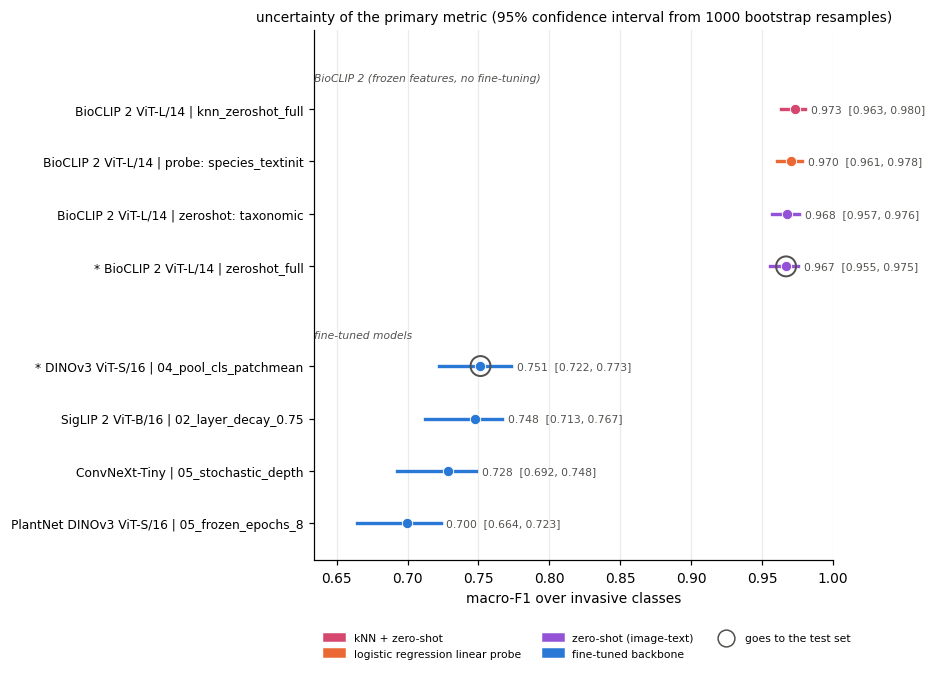

In [16]:
def macro_f1_from_counts(cm: np.ndarray, invasive_idx: np.ndarray) -> float:
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros_like(tp), where=(2 * tp + fp + fn) > 0)
    return float(f1[invasive_idx].mean())


def bootstrap_macro_f1(pred_frames: dict, labels: list, n_boot: int, seed: int):
    k = len(labels); idx = {l: i for i, l in enumerate(labels)}; inv_idx = np.array([i for i, l in enumerate(labels) if l != NONE_LABEL])
    ref = next(iter(pred_frames.values()))
    obs = ref["observation_id"].to_numpy(); y = ref["label"].map(idx).to_numpy()
    codes = {name: y * k + p.set_index("observation_id").loc[obs, "pred"].map(idx).to_numpy() for name, p in pred_frames.items()}
    rng = np.random.default_rng(seed); n = len(y)
    point = {name: macro_f1_from_counts(np.bincount(c, minlength=k * k).reshape(k, k), inv_idx) for name, c in codes.items()}
    boots = {name: np.empty(n_boot) for name in codes}
    for b in range(n_boot):
        sample = rng.integers(0, n, n)
        for name, c in codes.items():
            boots[name][b] = macro_f1_from_counts(np.bincount(c[sample], minlength=k * k).reshape(k, k), inv_idx)
    return point, pd.DataFrame(boots)


def delta_record(d: pd.Series) -> dict:
    return {"delta_ci95_low": float(d.quantile(0.025)), "delta_ci95_high": float(d.quantile(0.975)), "p_better": float((d > 0).mean())}


shortlist["pred_key"] = np.where(shortlist["selected"], "* ", "") + shortlist["short"]
labels_all = shortlist.iloc[0]["_metrics"].get("labels")
if not preds or not labels_all:
    print("bootstrap skipped: no val_predictions.csv or no label list in metrics_final.json")
    boot_table = None
else:
    point, boots = bootstrap_macro_f1(preds, labels_all, N_BOOTSTRAP, BOOTSTRAP_SEED)
    rows = []
    for s in SERIES:
        sub = shortlist[(shortlist["series"] == s) & shortlist["pred_key"].isin(preds)]
        if sub.empty:
            continue
        fin = sub[sub["selected"]]
        ref = fin["pred_key"].iloc[0] if len(fin) else None
        for _, r in sub.iterrows():
            name = r["pred_key"]
            if abs(float(r[SELECT_METRIC]) - point[name]) > 2e-3:
                warnings.warn(f"{name}: macro-F1 recomputed from val_predictions.csv ({point[name]:.4f}) differs from metrics_final.json ({r[SELECT_METRIC]:.4f})")
            row = {"run": name, "series": s, "selected": bool(r["selected"]), "kind": r["kind"], "macro_f1": point[name],
                   "ci95_low": float(boots[name].quantile(0.025)), "ci95_high": float(boots[name].quantile(0.975))}
            if ref is not None:
                row.update({"delta_vs_selected": point[name] - point[ref], **delta_record(boots[name] - boots[ref])})
            rows.append(row)
    boot_table = pd.DataFrame(rows).set_index("run")
    for c in ("delta_vs_selected", "delta_ci95_low", "delta_ci95_high", "p_better"):
        if c not in boot_table:
            boot_table[c] = np.nan
    boot_table["within_noise_of_selected"] = (boot_table["delta_ci95_low"] <= 0) & (0 <= boot_table["delta_ci95_high"]) & ~boot_table["selected"]
    boot_table.to_csv(OUT_DIR / "bootstrap_macro_f1.csv")
    display(blank(boot_table))
    for s in SERIES:
        sub = boot_table[boot_table["series"] == s]
        if sub.empty:
            continue
        fin = sub.index[sub["selected"]].tolist()
        noise = sub.index[sub["within_noise_of_selected"]].tolist()
        better = sub.index[(sub["delta_ci95_low"] > 0)].tolist()
        print(f"{SERIES[s]['label']}: selected model {fin[0] if fin else 'none'}; alternatives within validation noise of it: {noise or 'none'}"
              + (f"; alternatives SIGNIFICANTLY better than it: {better}" if better else ""))

    fin_keys = [(s, f["run"]) for s, f in selected_models.items() if f["run"] is not None]
    fin_keys = [(s, "* " + short_label(r)) for s, r in fin_keys if "* " + short_label(r) in preds]
    if len(fin_keys) > 1:
        print("\nselected models head to head: paired difference in macro-F1 (row minus column), 95% interval:")
        h2h = pd.DataFrame(index=[k for _, k in fin_keys], columns=[k for _, k in fin_keys], dtype=object)
        for _, a in fin_keys:
            for _, b in fin_keys:
                if a != b:
                    d = boots[a] - boots[b]; h2h.loc[a, b] = f"{point[a] - point[b]:+.4f} [{d.quantile(0.025):+.4f}, {d.quantile(0.975):+.4f}]"
        display(h2h.fillna(""))

    # figure: one block per series, rows ranked inside the block, color by kind, the selected model marked
    order, ygap, yy, labels_y = [], 0.9, [], []
    y = 0.0
    for s in reversed(list(SERIES)):
        sub = boot_table[boot_table["series"] == s].sort_values("macro_f1")
        if sub.empty:
            continue
        for name in sub.index:
            order.append(name); yy.append(y); y += 1.0
        labels_y.append((s, (yy[-len(sub)] + yy[-1]) / 2, yy[-1])); y += ygap
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(order) + 0.5 * len(labels_y) + 1.6))
    for name, yi in zip(order, yy):
        r = boot_table.loc[name]; color = KIND_COLORS[r["kind"]]
        ax.plot([r["ci95_low"], r["ci95_high"]], [yi, yi], color=color, lw=2.2)
        ax.scatter([r["macro_f1"]], [yi], color=color, s=46, zorder=3, edgecolors="white", linewidths=0.6)
        if r["selected"]:
            ax.scatter([r["macro_f1"]], [yi], s=170, facecolors="none", edgecolors=C_INK, linewidths=1.3, zorder=4)
        ax.text(r["ci95_high"] + 0.004, yi, f"{r['macro_f1']:.3f}  [{r['ci95_low']:.3f}, {r['ci95_high']:.3f}]", va="center", fontsize=7, color=C_INK)
    for s, _, y_top in labels_y:
        ax.text(0.0, y_top + 0.5, SERIES[s]["label"], transform=ax.get_yaxis_transform(), fontsize=7, color=C_INK, style="italic", va="bottom")
    ax.set_yticks(yy); ax.set_yticklabels(order, fontsize=8); ax.set_xlabel("macro-F1 over invasive classes")
    ax.set_xlim(max(0, boot_table["ci95_low"].min() - 0.03), min(1.0, boot_table["ci95_high"].max() + 0.16)); ax.set_ylim(-0.7, max(yy) + 1.5); ax.grid(axis="y", visible=False)
    handles = [Patch(color=KIND_COLORS[k], label=KIND_LABELS[k]) for k in dict.fromkeys(boot_table["kind"])]
    handles.append(Line2D([], [], marker="o", mfc="none", mec=C_INK, ms=11, ls="", label="goes to the test set"))
    ax.legend(handles=handles, fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3)
    ax.set_title(f"uncertainty of the primary metric (95% confidence interval from {N_BOOTSTRAP} bootstrap resamples)", fontsize=9)
    fig.tight_layout(); fig.savefig(OUT_DIR / "bootstrap_ci.png", bbox_inches="tight"); plt.show()

## 13. Record chosen models

Files are written to the `final_selection/` folder. The final training + test notebook will then read `final_models.json`: for a series of `test_protocol` "frozen" it loads `weights_file` (a `best.joblib` with the index, vocabulary and threshold, or the probe) and scores `test.csv` once; for a series of `test_protocol` "finetune" it trains the backbone on the full training set with `hyperparameters` (or `final_<series>_config.json`) and then scores `test.csv`. `threshold_val` is the threshold the run tuned on validation.

In [17]:
def run_record(r) -> dict:
    hp = copy.deepcopy(r["_config"]) if isinstance(r["_config"], dict) else {}
    if r["kind"] == "logreg" and not pd.isna(r["C"]):
        hp["C"] = float(r["C"])                                     # the C chosen by the sweep; config.json only has the grid
    return {"candidate": r["candidate"], "kind": r["kind"], "series": r["series"], "backbone": r["backbone"],
            "backbone_display": BACKBONES.get(r["backbone"], {}).get("display", r["family"]), "family": r["family"], "iteration": r["iteration"],
            "decision": r["decision"], "run_dir": r["run_dir"], "weights_file": f"{r['run_dir']}/{r['weights_file']}" if r["weights_file"] else None,
            "threshold_val": float(r["threshold"]) if not pd.isna(r["threshold"]) else None,
            "metrics": {k: (None if pd.isna(r[k]) else float(r[k])) for k in SCALAR_METRICS},
            "hyperparameters": hp}


models = {}
for s, f in selected_models.items():
    r = f["run"]
    if r is None:
        models[s] = None; continue
    rec = run_record(r)
    rec.update({"label": SERIES[s]["label"], "test_protocol": SERIES[s]["mode"], "chosen_by": f["rule"], "override": SERIES[s]["override"], "note": SERIES[s]["note"],
                "rule_pick": f["by_rule"]["candidate"] if f["by_rule"] is not None else None})
    if r["kind"] == "finetune":
        rec["changes_vs_finetune_baseline"] = config_changes(r, get_run(r["family"], "00_baseline"))
    key = "* " + short_label(r)
    if boot_table is not None and key in boot_table.index:
        b = boot_table.loc[key]; rec["bootstrap_ci95_macro_f1"] = [float(b["ci95_low"]), float(b["ci95_high"])]
    others = f["candidates"][f["candidates"]["candidate"] != r["candidate"]]
    rec["runner_up"] = None
    if len(others):
        ru = others.iloc[0]; ru_rec = run_record(ru); ru_rec["delta_" + SELECT_METRIC] = float(ru[SELECT_METRIC] - r[SELECT_METRIC])
        ru_key = short_label(ru)                                    # never selected, so no "* " prefix in boot_table
        if boot_table is not None and key in boot_table.index and ru_key in boot_table.index:
            d = boots[ru_key] - boots[key]
            ru_rec["delta_ci95"] = [float(d.quantile(0.025)), float(d.quantile(0.975))]
            ru_rec["within_validation_noise"] = bool(ru_rec["delta_ci95"][0] <= 0 <= ru_rec["delta_ci95"][1])
        rec["runner_up"] = ru_rec
    models[s] = rec
    json.dump(rec["hyperparameters"], open(OUT_DIR / f"final_{s}_config.json", "w"), indent=1, default=str)
    json.dump(r["_metrics"], open(OUT_DIR / f"final_{s}_val_metrics.json", "w"), indent=1, default=str)

final_models = {
    "selected_at": datetime.datetime.now().isoformat(timespec="seconds"), "runs_dir": str(RUNS_DIR.resolve()),
    "selection": {"metric": SELECT_METRIC, "kpi": KPI_METRIC, "finetune_rule": FINETUNE_SELECTION, "finetune_max_params_M": FINETUNE_MAX_PARAMS_M, "probe_of": PROBE_OF,
                  "series": {s: {k: v for k, v in SERIES[s].items()} for s in SERIES}},
    "models": models,
    "shortlist": [{"series": r["series"], "series_rank": int(r["series_rank"]), "selected": bool(r["selected"]), "candidate": r["candidate"], "kind": r["kind"],
                   "backbone": r["backbone"], SELECT_METRIC: float(r[SELECT_METRIC]), KPI_METRIC: float(r[KPI_METRIC]), "threshold": float(r["threshold"])}
                  for _, r in shortlist.iterrows()],
    "backbones_not_run": [k for k, r in zip(comparison["key"], comparison["status"]) if r == "not run"],
    "notes": ["All metrics are validation metrics (val.csv). test.csv and test_unseen.csv were not read.",
              "test_protocol 'frozen': load weights_file and score the test set once; nothing is trained. "
              "test_protocol 'finetune': train the backbone on the full training set with hyperparameters, then score the test set.",
              "threshold_val is the threshold tuned on validation for this run; the final notebook decides how a retrained model gets its threshold.",
              "hyperparameters is the run's config.json (plus C for a logistic-regression probe); for a fine-tune it is the complete input of train_and_evaluate."],
}
json.dump(final_models, open(OUT_DIR / "final_models.json", "w"), indent=1, default=str)
for stale in ("best_model.json", "best_model_config.json", "best_model_val_metrics.json", "candidates.csv",                 # outputs of the single-winner version
              "final_siglip2_config.json", "final_siglip2_val_metrics.json", "iteration_trajectories_siglip2.png", "false_flags_by_group.png"):   # ... and of the three-series version
    if (OUT_DIR / stale).exists():
        (OUT_DIR / stale).unlink(); print(f"removed stale {stale}")

for s, rec in models.items():
    if rec is None:
        print(f"{SERIES[s]['label']}: NOTHING RUN YET"); continue
    print(f"FINAL MODEL, {SERIES[s]['label']}: {rec['candidate']}  ({KIND_LABELS[rec['kind']]}; {rec['chosen_by']})")
    print("  " + " | ".join(f"{k} {rec['metrics'][k]:.4f}" for k in KEY_METRICS if rec["metrics"][k] is not None))
    if rec["kind"] == "finetune":
        print("  hyperparameters changed from the fine-tune baseline:", rec["changes_vs_finetune_baseline"] or "none")
    elif rec["kind"] == "logreg":
        print(f"  logistic regression C = {rec['hyperparameters'].get('C')}, standardize = {rec['hyperparameters'].get('standardize')}")
    else:
        print("  method:", {k: rec["hyperparameters"][k] for k in METHOD_FIELDS if k in rec["hyperparameters"]} or f"see {rec['family']}'s notebook")
    if rec["rule_pick"] and rec["rule_pick"] != rec["candidate"]:
        print(f"  the rule would have picked {rec['rule_pick']}; note: {rec['note']}")
    if rec["runner_up"]:
        ru = rec["runner_up"]; msg = f"  runner-up in the series: {ru['candidate']} ({ru['delta_' + SELECT_METRIC]:+.4f} {SELECT_METRIC})"
        if "delta_ci95" in ru:
            msg += f", 95% CI of the difference [{ru['delta_ci95'][0]:+.4f}, {ru['delta_ci95'][1]:+.4f}]" + (" -> within validation noise" if ru["within_validation_noise"] else "")
        print(msg)
print("written:", sorted(p.name for p in OUT_DIR.iterdir()))

FINAL MODEL, BioCLIP 2 (frozen features, no fine-tuning): bioclip2_zeroshot_full/00_baseline  (zero-shot (image-text); SERIES['bioclip2']['override'])
  macro_f1_invasive 0.9668 | top1_acc_all 0.9823 | macro_ap_invasive 0.9897 | top1_recall_invasive 0.9756 | top3_recall_invasive 0.9929 | bin_precision_invasive 0.9815 | bin_recall_invasive 0.9705 | bin_auroc_invasive 0.9983 | noninv_auroc 0.9983 | threshold 0.0600
  method: {'method': 'zero_shot', 'vocab_size': 4573, 'prompt': 'scientific'}
  the rule would have picked bioclip2_knn_zeroshot_full/00_baseline; note: The rule picks bioclip2_knn_zeroshot_full (val macro-F1 0.973), which ties with bioclip2_zeroshot_full (0.967; 95% interval of the paired difference -0.014 to +0.002). In the unknown-species rehearsal of notebook 06 (species hidden from the model on val) the kNN + zero-shot combination flags 10-15% of the unknown-species photos as invasive against about 4% for zero-shot-full, so zero-shot-full is the better model for the test 

## Notes

* Re-run the whole notebook after any experiment notebook finishes an iteration or after new BioCLIP 2 runs: every table, figure and file in `final_selection/` is rebuilt from scratch (overwritten; nothing is appended).
* `FINETUNE_SELECTION`, `SERIES[...]["override"]` and the series each backbone belongs to (`BACKBONES[key]["series"]`) in Section 1 change the outcome; the rule or override that decided each series is recorded in `final_models.json["models"][<series>]["chosen_by"]`, with the note.
* The SigLIP 2 fine-tuning notebook's `decisions.json` on Drive was rebuilt from the notebook outputs of its first series of iterations (00 to 04); the runs 05 to 09 in that folder were trained on the baseline configuration after the file was lost, so they appear as undecided in Section 5 and do not take part in the selection.